# Preprocess: Clustering

In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('dataset.csv')

df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [100]:
def data_quality_report(df):

    if isinstance(df, pd.core.frame.DataFrame):

        descriptive_statistics = df.describe(include = 'all')
        data_types = pd.DataFrame(df.dtypes, columns=['Data Type']).transpose()
        missing_value_counts = pd.DataFrame(df.isnull().sum(), columns=['Missing Values']).transpose()
        present_value_counts = pd.DataFrame(df.count(), columns=['Present Values']).transpose()
        data_report = pd.concat([descriptive_statistics, data_types, missing_value_counts, present_value_counts], axis=0)

        return data_report

    else:

        return None

data_quality_report(df)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
count,4424.0,4424.0,4424.0,4424.0,4424.0,4424.0,4424.0,4424.0,4424.0,4424.0,...,4424.0,4424.0,4424.0,4424.0,4424.0,4424.0,4424.0,4424.0,4424.0,4424
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graduate
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2209
mean,1.178571,6.88698,1.727848,9.899186,0.890823,2.53142,1.254521,12.322107,16.455244,7.317812,...,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969,NaN
std,0.605747,5.298964,1.313793,4.331792,0.311897,3.963707,1.748447,9.026251,11.0448,3.997828,...,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.66385,1.382711,2.269935,NaN
min,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,7.6,-0.8,-4.06,NaN
25%,1.0,1.0,1.0,6.0,1.0,1.0,1.0,2.0,3.0,5.0,...,0.0,5.0,6.0,2.0,10.75,0.0,9.4,0.3,-1.7,NaN
50%,1.0,8.0,1.0,10.0,1.0,1.0,1.0,13.0,14.0,6.0,...,0.0,6.0,8.0,5.0,12.2,0.0,11.1,1.4,0.32,NaN
75%,1.0,12.0,2.0,13.0,1.0,1.0,1.0,22.0,27.0,10.0,...,0.0,7.0,10.0,6.0,13.333333,0.0,13.9,2.6,1.79,NaN


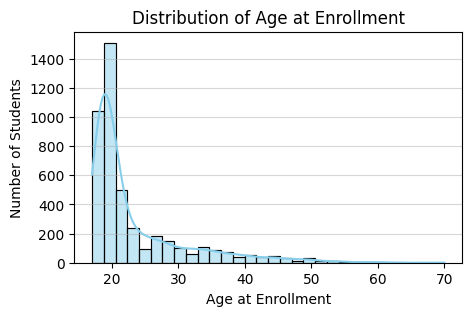

In [101]:
# Set figure size
plt.figure(figsize=(5, 3))

# Create histogram with Kernel Density Estimate (KDE) line
sns.histplot(df['Age at enrollment'], kde=True, bins=30, color='skyblue')

# Add labels and title
plt.title('Distribution of Age at Enrollment')
plt.xlabel('Age at Enrollment')
plt.ylabel('Number of Students')
plt.grid(axis='y', alpha=0.5)

# Show the plot
plt.show()

In [102]:
# FILTERING
# Remove Application mode = 9
df_clean = df[df['Application order'] != 9].copy()

# Remove Nacionality feature entirely
if 'Nacionality' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Nacionality'])

# Remove Mother's and Father's occupation = 46
df_clean = df_clean[df_clean["Mother's occupation"] != 46]
df_clean = df_clean[df_clean["Father's occupation"] != 46]

df_clean.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,13,10,6,10,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,3,4,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,22,27,10,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,23,27,6,4,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,22,28,10,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [103]:
# ------ Clustering / Grouping ------

# --- Marital Status ---
conditions_marital = [
    df_clean['Marital status'] == 1,             # Single
    df_clean['Marital status'].isin([2, 5]),     # Partnered (Married, Common Law Marriage)
    df_clean['Marital status'].isin([3, 4, 6])   # From Partnered to Alone (Widowed, Divorced, Legally Separated)
]
choices_marital = ['Single', 'Partnered', 'Partnered_to_Alone']
df_clean['Marital_Group'] = np.select(conditions_marital, choices_marital, default='Other')
df_clean = df_clean.drop(columns=['Marital status'])

# --- Application Mode ---
# 1. General Entry: 1, 8, 9 (1st, 2nd, 3rd Phase)
# 2. Special / Mature: 2, 5, 10, 11 (Ordinances), 3, 7 (Islands), 6 (International)
# 3. Transfer / Advanced: 4 (Degree Holders), 12-16 (Transfers), 17 (Short Cycle), 18 (Others)

conditions_app = [
    df_clean['Application mode'].isin([1, 8, 9]),            # General Entry
    df_clean['Application mode'].isin([2, 3, 5, 6, 7, 10, 11]), # Special / Mature
    df_clean['Application mode'].isin([4, 12, 13, 14, 15, 16, 17, 18]) # Transfer / Advanced
]

choices_app = ['General Entry', 'Special / Mature', 'Transfer / Advanced']
df_clean['Application_Mode_Group'] = np.select(conditions_app, choices_app, default='Other')
df_clean = df_clean.drop(columns=['Application mode'])

# --- Course ---
# 1. STEM: Informatics (7)
# 2. Agriculture: Biofuel (1), Agronomy (4), Vet Nursing (6), Equine (8)
# 3. Health: Nursing (12), Oral Hygiene (13)
# 4. Arts: Animation (2), Design (5), Journalism (15)
# 5. Social/Ed: Social Service (3, 10), Basic Ed (16)
# 6. Business: Management (9, 17), Tourism (11), Marketing (14)

conditions_course = [
    df_clean['Course'].isin([7]),            # STEM
    df_clean['Course'].isin([1, 4, 6, 8]), # Agriculture
    df_clean['Course'].isin([12, 13]), # Health
    df_clean['Course'].isin([2, 5, 15]),            # Arts
    df_clean['Course'].isin([3, 10, 16]), # Social/Ed
    df_clean['Course'].isin([9, 11, 14, 17]) # Business
]

choices_course = ['STEM', 'Agriculture', 'Health', 'Arts', 'Social/Ed', 'Business']
df_clean['Course_Group'] = np.select(conditions_course, choices_course, default='Other')
df_clean = df_clean.drop(columns=['Course'])

# --- Previous Qualification ---
# 1. Secondary: 1 (Standard)
# 2. Higher Ed: 2, 3, 4, 5, 6, 15, 17
# 3. Vocational: 14 (Tech Specialization), 16 (Pro Technical)
# 4. Basic/Lower: 7, 8, 9, 10, 11, 12, 13 (Incomplete or Basic cycles)

conditions_pre_qual = [
    df_clean['Previous qualification'].isin([1]), # Secondary
    df_clean['Previous qualification'].isin([2, 3, 4, 5, 6, 15, 17]), # Higher Ed
    df_clean['Previous qualification'].isin([14, 16]), # Vocational
    df_clean['Previous qualification'].isin([7, 8, 9, 10, 11, 12, 13]) # Basic/Lower
]

choices_pre_qual = ['Secondary', 'Higher Ed', 'Vocational', 'Basic/Lower']
df_clean['Previous_Qualification_Group'] = np.select(conditions_pre_qual, choices_pre_qual, default='Other')
df_clean = df_clean.drop(columns=['Previous qualification'])

# --- Mother's / Father's Qualification ---
# 1. Secondary: 1 (Standard)
# 2. Higher Ed: 2, 3, 4, 5, 6, 30, 31, 32, 33, 34
# 3. Basic/Lower: The rest

conditions_mom_qual = [
    df_clean['Mother\'s qualification'].isin([1]), # Secondary
    df_clean['Mother\'s qualification'].isin([2, 3, 4, 5, 6, 30, 31, 32, 33, 34]), # Higher Ed
]

choices_mom_qual = ['Secondary_Ed', 'Higher_Ed']
df_clean['Mother_Qualification_Group'] = np.select(conditions_mom_qual, choices_mom_qual, default='Basic_Lower_Ed')
df_clean = df_clean.drop(columns=['Mother\'s qualification'])

conditions_dad_qual = [
    df_clean['Father\'s qualification'].isin([1]), # Secondary
    df_clean['Father\'s qualification'].isin([2, 3, 4, 5, 6, 30, 31, 32, 33, 34]), # Higher Ed
]

choices_dad_qual = ['Secondary_Ed', 'Higher_Ed']
df_clean['Father_Qualification_Group'] = np.select(conditions_dad_qual, choices_dad_qual, default='Basic_Lower_Ed')
df_clean = df_clean.drop(columns=['Father\'s qualification'])

# --- Mother's / Father's Occupation ---

conditions_mom_job = [
        # 1. Managerial & Professional
        # 2, 3 AND 16-19, 21-24
        df_clean['Mother\'s occupation'].isin([2, 3, 16, 17, 18, 19, 21, 22, 23, 24]),
        
        # 2. Technician & Admin
        # 4, 5, 25-28 AND 30
        df_clean['Mother\'s occupation'].isin([4, 5, 25, 26, 27, 28, 30]),
        
        # 3. Service & Security
        # 6 (Service), 11, 13, 14, 15 (Armed Forces), 20 (Teacher), 29, 31-32
        df_clean['Mother\'s occupation'].isin([6, 11, 13, 14, 15, 20, 29, 31, 32]),
        
        # 4. Skilled Manual
        # 7, 8, 9, 33-44
        df_clean['Mother\'s occupation'].isin([7, 8, 9]) | (df_clean['Mother\'s occupation'] >= 33) & (df_clean['Mother\'s occupation'] <= 44),
        
        # 5. Unskilled & Student
        # 1, 10, 12, 45
        df_clean['Mother\'s occupation'].isin([1, 10, 12, 45])
    ]

choices_mom_job = ['Managerial_Professional',
        'Technician_Admin', 
        'Service_Security',
        'Skilled_Manual',
        'Unskilled_Student']

df_clean['Mother_Occupation_Group'] = np.select(conditions_mom_job, choices_mom_job, default='Other')
df_clean = df_clean.drop(columns=['Mother\'s occupation'])

#Father's, new categories same as Mother's
conditions_dad_job = [
    
        df_clean['Father\'s occupation'].isin([2, 3, 16, 17, 18, 19, 21, 22, 23, 24]),
      
        df_clean['Father\'s occupation'].isin([4, 5, 25, 26, 27, 28, 30]),
        
        df_clean['Father\'s occupation'].isin([6, 11, 13, 14, 15, 20, 29, 31, 32]),
        
        df_clean['Father\'s occupation'].isin([7, 8, 9]) | ((df_clean['Father\'s occupation'] >= 33) & (df_clean['Father\'s occupation'] <= 44)),
        
        df_clean['Father\'s occupation'].isin([1, 10, 12, 45])
]

choices_dad_job = ['Managerial_Professional', 
        'Technician_Admin', 
        'Service_Security',
        'Skilled_Manual',
        'Unskilled_Student']

df_clean['Father_Occupation_Group'] = np.select(conditions_dad_job, choices_dad_job, default='Other')
df_clean = df_clean.drop(columns=['Father\'s occupation'])

# --- Age at enrollment ---
# 1. Age <= 20, standard enrollment
# 2. 21 <= Age <= 25, later enrollment
# 3. Age > 25, late enrollment
# No removal of original 'Age at enrollment' column


conditions_target = [
    df_clean['Age at enrollment'] <= 20, # standard enrollment
    df_clean['Age at enrollment'].between(21, 25), # later enrollment
    df_clean['Age at enrollment'] > 25 # late enrollment
]

choices_target = ['Standard enrollment', 'Later enrollment', 'Late enrollment']
df_clean['Age_Group'] = np.select(conditions_target, choices_target, default='Other')
df_clean = df_clean.drop(columns=['Age at enrollment'])

# --- Target ---
# Dropout vs. Graduate + Enrolled

conditions_target = [
    df_clean['Target'].isin(['Graduate', 'Enrolled']), # Non-Dropout
    df_clean['Target'].isin(['Dropout'])
]

choices_target = ['Non-Dropout', 'Dropout']
df_clean['Target_Group'] = np.select(conditions_target, choices_target, default='Other')
df_clean = df_clean.drop(columns=['Target'])

df_clean.head()

,Application order,Daytime/evening attendance,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,International,Curricular units 1st sem (credited),...,Marital_Group,Application_Mode_Group,Course_Group,Previous_Qualification_Group,Mother_Qualification_Group,Father_Qualification_Group,Mother_Occupation_Group,Father_Occupation_Group,Age_Group,Target_Group
0,5,1,1,0,0,1,1,0,0,0,...,Single,General Entry,Arts,Secondary,Basic_Lower_Ed,Basic_Lower_Ed,Service_Security,Unskilled_Student,Standard enrollment,Dropout
1,1,1,1,0,0,0,1,0,0,0,...,Single,Special / Mature,Business,Secondary,Secondary_Ed,Higher_Ed,Technician_Admin,Technician_Admin,Standard enrollment,Non-Dropout
2,5,1,1,0,0,0,1,0,0,0,...,Single,General Entry,Arts,Secondary,Basic_Lower_Ed,Basic_Lower_Ed,Unskilled_Student,Unskilled_Student,Standard enrollment,Dropout
3,2,1,1,0,0,1,0,0,0,0,...,Single,General Entry,Arts,Secondary,Basic_Lower_Ed,Basic_Lower_Ed,Service_Security,Technician_Admin,Standard enrollment,Non-Dropout
4,1,0,0,0,0,1,0,0,0,0,...,Partnered,Transfer / Advanced,Social/Ed,Secondary,Basic_Lower_Ed,Basic_Lower_Ed,Unskilled_Student,Unskilled_Student,Late enrollment,Non-Dropout


In [104]:
data_quality_report(df_clean)

,Application order,Daytime/evening attendance,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,International,Curricular units 1st sem (credited),...,Marital_Group,Application_Mode_Group,Course_Group,Previous_Qualification_Group,Mother_Qualification_Group,Father_Qualification_Group,Mother_Occupation_Group,Father_Occupation_Group,Age_Group,Target_Group
count,4422.0,4422.0,4422.0,4422.0,4422.0,4422.0,4422.0,4422.0,4422.0,4422.0,...,4422,4422,4422,4422,4422,4422,4422,4422,4422,4422
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3,3,6,4,3,3,5,5,3,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Single,General Entry,Business,Secondary,Basic_Lower_Ed,Basic_Lower_Ed,Unskilled_Student,Skilled_Manual,Standard enrollment,Non-Dropout
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3917,2703,1167,3715,2758,3098,1790,1277,2550,3001
mean,1.726368,0.891,0.548394,0.011533,0.113749,0.880597,0.351651,0.248304,0.024876,0.710312,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.309484,0.311675,0.497709,0.106784,0.317543,0.324299,0.47754,0.432078,0.155764,2.360992,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Training

## STEP 0: Imports & evaluation loss

In [105]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

import warnings
warnings.filterwarnings('ignore')


from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, confusion_matrix, log_loss, roc_curve
)
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import shap

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier

# ---- Evaluation loss: FN = miss dropout, FP = unnecessary intervention ----
def evaluation_loss(y_true, scores, threshold, cost_fn=4000, cost_fp=500, cost_tn=0, cost_tp=-1000): #custom loss here
    """
    y_true  : array-like of 0/1 labels (1=Dropout)
    scores  : continuous scores (probabilities or raw scores)
    threshold : cut-off on scores to classify as dropout
    """
    # If scores are not in [0,1], normalise them
    s = np.asarray(scores)
    if s.min() < 0 or s.max() > 1:
        s = (s - s.min()) / (s.max() - s.min() + 1e-8)

    y_pred = (s >= threshold).astype(int)

    FN = np.sum((y_true == 1) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    TP = np.sum((y_true == 1) & (y_pred == 1))

    return cost_fn * FN + cost_fp * FP + cost_tn * TN + cost_tp * TP


## STEP 1: Build X, y and split (train & val + test)

In [106]:
# 1.1 Binary target: 1 = Dropout, 0 = Non-Dropout
df_model = df_clean.copy()

df_model = df_model[df_model['Target_Group'].isin(['Dropout', 'Non-Dropout'])].copy()
df_model['is_dropout'] = (df_model['Target_Group'] == 'Dropout').astype(int)

# Drop original grouped target
df_model = df_model.drop(columns=['Target_Group'])

# 1.2 Features and target
X = df_model.drop(columns=['is_dropout'])
y = df_model['is_dropout'].values

print("Shape X:", X.shape, "Shape y:", y.shape)

# 1.3 Identify numeric / categorical columns
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Numeric cols:", len(numeric_cols))
print("Categorical cols:", len(categorical_cols))

# 1.4 Split: Train + Val / Test

X_train_n_val, X_test, y_train_n_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=16, stratify=y
)

print("Train & Val:", X_train_n_val.shape)
print("Test: ", X_test.shape)

Shape X: (4422, 33) Shape y: (4422,)
Numeric cols: 24
Categorical cols: 9
Train & Val: (3537, 33)
Test:  (885, 33)


## STEP 2: Column transformers

In [ ]:

# For glassbox linear models
preprocessor_linear = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ]
)

# For tree-based models
preprocessor_tree = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols), #leave numeric features unchanged (no scaling) for tree-based models.
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ]
)

## STEP 3: Glassbox model

### STEP 3a: train


Training Linear_L2
Fold 1: AUC=0.5604, Threshold=0.310, Loss=26,500
Fold 2: AUC=0.6313, Threshold=0.120, Loss=18,500
Fold 3: AUC=0.5897, Threshold=0.200, Loss=32,500
Fold 4: AUC=0.2488, Threshold=0.100, Loss=70,000

Linear_L2 - Cross-Validation Results (Average):
CV AUC: 0.5076 (+/- 0.1515)
CV Custom Loss: 36,875 (+/- 19759)
Average Optimal Threshold: 0.182

Average Validation Confusion Matrix:
                Predicted
                 0      1
Actual 0      291    309
Actual 1      138    146

Test AUC: 0.5655
Test Custom Loss: 89,500

Test Confusion Matrix:
                Predicted
                 0      1
Actual 0      358    243
Actual 1      137    147

Training Linear_Logloss
Fold 1: AUC=0.9136, Threshold=0.140, Loss=-64,000
Fold 2: AUC=0.8986, Threshold=0.120, Loss=-52,500
Fold 3: AUC=0.8708, Threshold=0.120, Loss=26,000
Fold 4: AUC=0.8965, Threshold=0.100, Loss=-30,000

Linear_Logloss - Cross-Validation Results (Average):
CV AUC: 0.8949 (+/- 0.0154)
CV Custom Loss: -30,125 

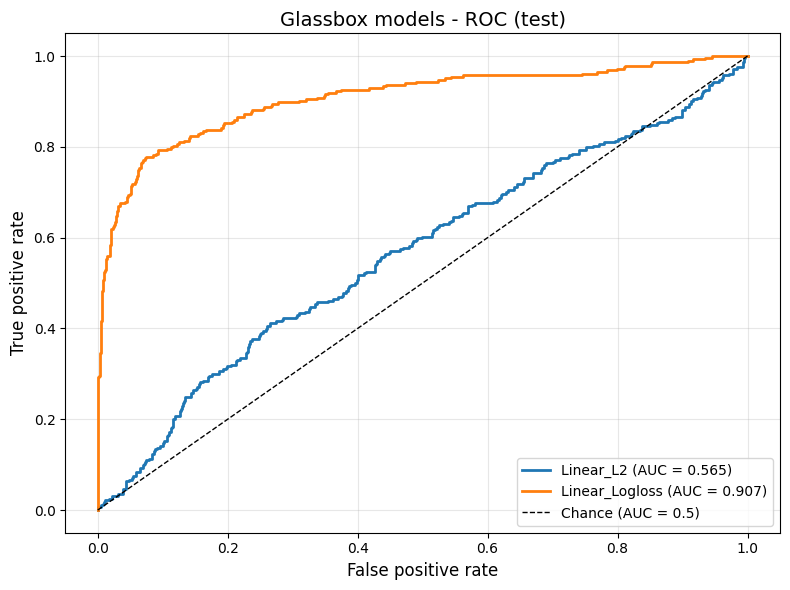

In [ ]:

# Define models with different losses
# L2 loss (standard logistic regression) vs Hinge loss (SVM-like)
models_glassbox = {
    'Linear_L2': SGDClassifier(loss='squared_error', penalty='l2',  max_iter=1000, random_state=42),
    'Linear_Logloss': SGDClassifier(loss='log_loss', penalty='l2', max_iter=1000, random_state=42) #Seed for the random number generator used for random shuffling/initialization 
}

# Cross-validation setup
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

# Train and evaluate glassbox models
results_glassbox = {}

for name, clf in models_glassbox.items():
    print(f"\n{'='*60}")
    print(f"Training {name}")
    print('='*60)
    
    # Create pipeline
    model = Pipeline([
        ('preprocessor', preprocessor_linear),
        ('classifier', clf)
    ])
    
    # Store CV results
    cv_aucs = []
    cv_losses = []
    cv_cms = []
    cv_thresholds = []
    
    fold = 1
    for train_idx, val_idx in cv.split(X_train_n_val, y_train_n_val):
        X_train_fold = X_train_n_val.iloc[train_idx]
        y_train_fold = y_train_n_val[train_idx]
        X_val_fold = X_train_n_val.iloc[val_idx]
        y_val_fold = y_train_n_val[val_idx]
        
        # Fit model
        model.fit(X_train_fold, y_train_fold)
        
        # Get decision function or probability
        if hasattr(model.named_steps['classifier'], 'predict_proba'):
            y_val_proba = model.predict_proba(X_val_fold)[:, 1]
        else:
            y_val_proba = model.decision_function(X_val_fold)
        
        # Calculate AUC
        fold_auc = roc_auc_score(y_val_fold, y_val_proba)
        cv_aucs.append(fold_auc)
        
        # Find optimal threshold for this fold
        best_threshold = 0.5
        best_loss = float('inf')
        
        for thresh in np.arange(0.1, 0.9, 0.01):
            loss = evaluation_loss(y_val_fold, y_val_proba, thresh)
            if loss < best_loss:
                best_loss = loss
                best_threshold = thresh
        
        cv_thresholds.append(best_threshold)
        cv_losses.append(best_loss)
        
        # Confusion matrix for this fold
        y_val_pred = (y_val_proba >= best_threshold).astype(int)
        cm_fold = confusion_matrix(y_val_fold, y_val_pred)
        cv_cms.append(cm_fold)
        
        print(f"Fold {fold}: AUC={fold_auc:.4f}, Threshold={best_threshold:.3f}, Loss={best_loss:,.0f}")
        fold += 1
    
    # Average CV metrics
    avg_cv_auc = np.mean(cv_aucs)
    avg_cv_loss = np.mean(cv_losses)
    avg_threshold = np.mean(cv_thresholds)
    avg_cm = np.mean(cv_cms, axis=0).astype(int)
    
    print(f"\n{name} - Cross-Validation Results (Average):")
    print(f"CV AUC: {avg_cv_auc:.4f} (+/- {np.std(cv_aucs):.4f})")
    print(f"CV Custom Loss: {avg_cv_loss:,.0f} (+/- {np.std(cv_losses):.0f})")
    print(f"Average Optimal Threshold: {avg_threshold:.3f}")
    
    print("\nAverage Validation Confusion Matrix:")
    print(f"                Predicted")
    print(f"                 0      1")
    print(f"Actual 0    {avg_cm[0,0]:5d}  {avg_cm[0,1]:5d}")
    print(f"Actual 1    {avg_cm[1,0]:5d}  {avg_cm[1,1]:5d}")
    
    # Train final model on full train+val set
    model.fit(X_train_n_val, y_train_n_val)
    
    # Test set evaluation
    if hasattr(model.named_steps['classifier'], 'predict_proba'):
        y_test_proba = model.predict_proba(X_test)[:, 1]
    else:
        y_test_proba = model.decision_function(X_test)
    
    test_auc = roc_auc_score(y_test, y_test_proba)
    
    # Use average threshold from CV
    test_loss = evaluation_loss(y_test, y_test_proba, avg_threshold)
    y_test_pred = (y_test_proba >= avg_threshold).astype(int)
    cm_test = confusion_matrix(y_test, y_test_pred)
    
    print(f"\nTest AUC: {test_auc:.4f}")
    print(f"Test Custom Loss: {test_loss:,.0f}")
    
    print("\nTest Confusion Matrix:")
    print(f"                Predicted")
    print(f"                 0      1")
    print(f"Actual 0    {cm_test[0,0]:5d}  {cm_test[0,1]:5d}")
    print(f"Actual 1    {cm_test[1,0]:5d}  {cm_test[1,1]:5d}")
    
    # Store results
    results_glassbox[name] = {
        'model': model,
        'cv_auc': avg_cv_auc,
        'test_auc': test_auc,
        'threshold': avg_threshold,
        'cv_loss': avg_cv_loss,
        'test_loss': test_loss,
        'cv_cm': avg_cm,
        'cm_test': cm_test,
        'y_test_proba': y_test_proba
    }

# Plot ROC curves for glassbox models
plt.figure(figsize=(8, 6))
for name, results in results_glassbox.items():
    fpr, tpr, _ = roc_curve(y_test, results['y_test_proba'])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {results['test_auc']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance (AUC = 0.5)')
plt.xlabel('False positive rate', fontsize=12)
plt.ylabel('True positive rate', fontsize=12)
plt.title('Glassbox models - ROC (test)', fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Step 3b: Interpret

In [ ]:
print(f"\n{'='*80}")
print("INTERPRETATION OF ALL GLASSBOX MODELS (RANKED BY CV CUSTOM LOSS)")
print('='*80)

# Sort glassbox models by CV custom loss (best to worst)
sorted_glassbox = sorted(results_glassbox.items(), key=lambda x: x[1]['cv_loss'])

for rank, (name, results) in enumerate(sorted_glassbox, 1): #enumerate (sorted_glassbox, 1) returns (index, item) pairs where indexing starts at 1.
    print(f"\n{'#'*80}")
    print(f"RANK {rank}: {name}")
    print(f"CV Custom Loss: {results['cv_loss']:,.0f} | Test Custom Loss: {results['test_loss']:,.0f}")
    print('#'*80)
    
    # Get feature names after preprocessing
    feature_names = (numeric_cols + 
                    list(results['model'].named_steps['preprocessor']
                         .named_transformers_['cat'].get_feature_names_out(categorical_cols)))
    
    # Get coefficients
    classifier = results['model'].named_steps['classifier']
    
    if hasattr(classifier, 'coef_'): #whether the fitted model object classifier has a coefficient attribute named coef_
        coefs = classifier.coef_[0] if len(classifier.coef_.shape) > 1 else classifier.coef_
        intercept = classifier.intercept_[0] if hasattr(classifier, 'intercept_') else 0
        
        # Create coefficient dataframe
        coef_df = pd.DataFrame({
            'Feature': feature_names,
            'Coefficient': coefs
        }).sort_values('Coefficient', key=abs, ascending=False)
        
        print(f"\nIntercept: {intercept:.4f}")
        print("\nTop 20 Features by Absolute Coefficient:")
        print(coef_df.head(20).to_string(index=False))
        
        # Regression formula (top 10 features)
        print(f"\nSimplified Regression Formula (Top 10 features):")
        print(f"log(p/(1-p)) = {intercept:.4f}")
        for idx, row in coef_df.head(10).iterrows():
            sign = '+' if row['Coefficient'] > 0 else ''
            print(f"    {sign}{row['Coefficient']:8.4f} * {row['Feature']}")
    else:
        print("\nModel does not have interpretable coefficients.")


INTERPRETATION OF ALL GLASSBOX MODELS (RANKED BY CV CUSTOM LOSS)

################################################################################
RANK 1: Linear_Logloss
CV Custom Loss: -30,125 | Test Custom Loss: -46,500
################################################################################

Intercept: -4.1844

Top 20 Features by Absolute Coefficient:
                                       Feature  Coefficient
           Curricular units 2nd sem (approved)    -2.295200
           Curricular units 2nd sem (enrolled)     1.118223
        Previous_Qualification_Group_Higher Ed     1.090387
           Curricular units 1st sem (approved)    -1.020254
                       Tuition fees up to date    -0.904542
                     Age_Group_Late enrollment     0.896508
          Application_Mode_Group_General Entry     0.745224
      Father_Occupation_Group_Technician_Admin     0.548774
    Application_Mode_Group_Transfer / Advanced     0.542222
     Mother_Qualification_Group_Ba

## STEP 4: Blackbox models

### STEP 4a: Train


################################################################################
Training RandomForest_L2 with Hyperparameter Tuning
################################################################################

Parameter Grid:
  n_estimators: [100, 150, 200]
  max_depth: [5, 10, 15]
  min_samples_split: [10, 20]

Total combinations to test: 18
Performing Grid Search with 4-fold CV...

Fitting model...
Fitting 4 folds for each of 18 candidates, totalling 72 fits

Best Parameters Found:
  max_depth: 5
  min_samples_split: 10
  n_estimators: 100
Best CV AUC Score: nan
Fold 1: Train_AUC=0.9267, Val_AUC=0.9126, Threshold=0.120, Loss=-62,500
Fold 2: Train_AUC=0.9336, Val_AUC=0.9037, Threshold=0.100, Loss=-60,000
Fold 3: Train_AUC=0.9310, Val_AUC=0.9026, Threshold=0.110, Loss=-69,500
Fold 4: Train_AUC=0.9322, Val_AUC=0.9058, Threshold=0.130, Loss=-67,000

RandomForest_L2 - Cross-Validation Results (Average with Best Params):
Train AUC: 0.9309
CV AUC: 0.9062 (+/- 0.0039)
Overfitting Gap: 

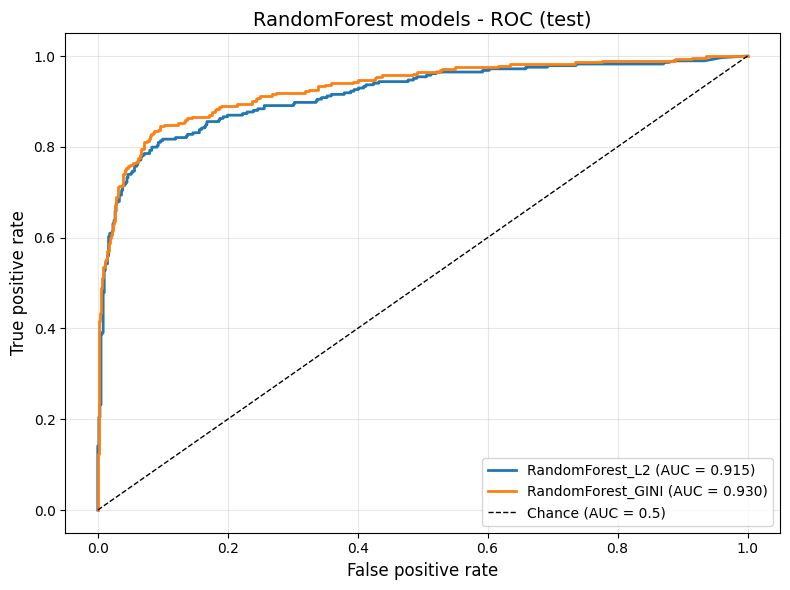

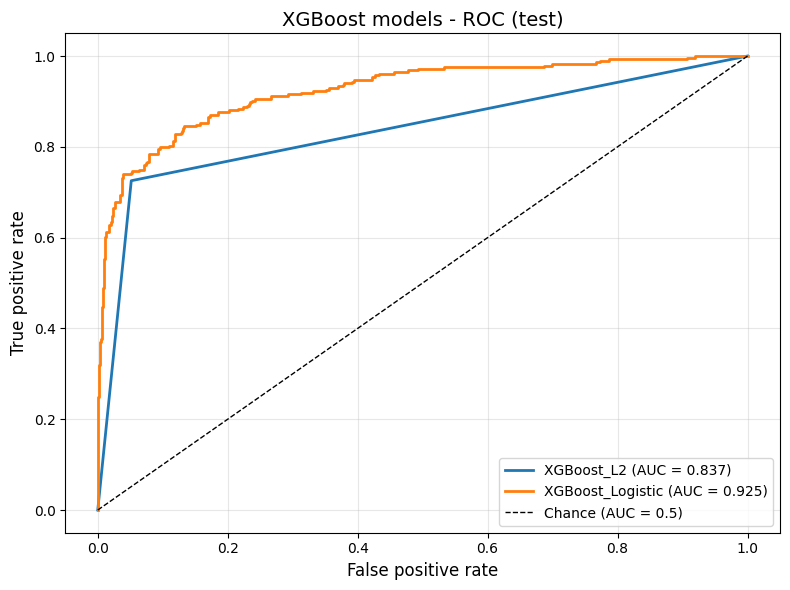

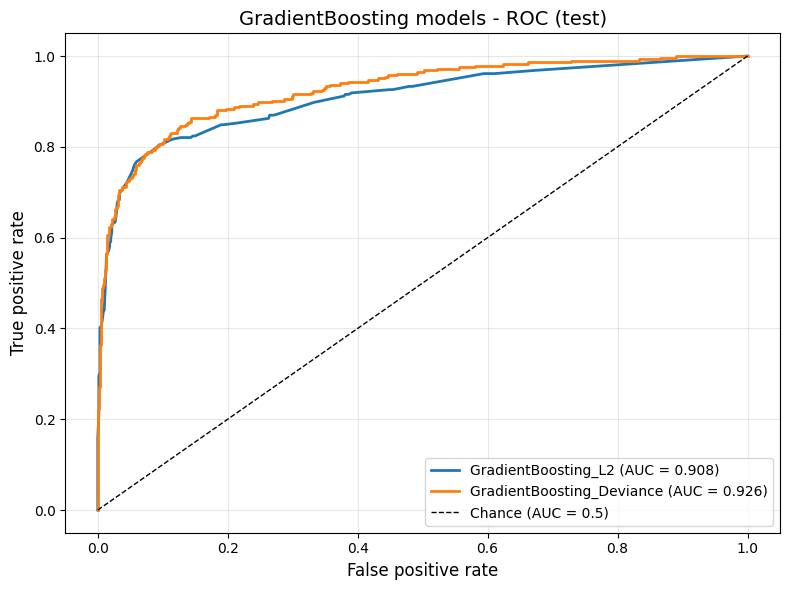

In [ ]:
from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV
import shap

# Define parameter grids for hyperparameter tuning
param_grids = {
    'RandomForest_L2': {
        'n_estimators': [100, 150, 200],
        'max_depth': [5, 10, 15],
        'min_samples_split': [10, 20]
    },
    'RandomForest_GINI': {
        'n_estimators': [100, 150, 200],
        'max_depth': [5, 10, 15],
        'min_samples_split': [10, 20],        
        'criterion': ['gini']
    },
    'XGBoost_L2': {
        'n_estimators': [100, 200],
        'max_depth': [3, 5, 7, 9],
        'learning_rate': [0.01, 0.1, 0.3]
        # 'min_child_weight': [1, 3, 5],
        # 'subsample': [0.8, 1.0],
        # 'colsample_bytree': [0.8, 1.0],
        # 'reg_alpha': [0, 0.1],
        # 'reg_lambda': [1.0, 2.0]
    },
    'XGBoost_Logistic': {
        'n_estimators': [100, 200],
        'max_depth': [3, 5, 7, 9],
        'learning_rate': [0.01, 0.1, 0.3]
        # 'min_child_weight': [1, 3, 5],
        # 'subsample': [0.8, 1.0],
        # 'colsample_bytree': [0.8, 1.0],
        # 'reg_alpha': [0, 0.1],
        # 'reg_lambda': [1.0, 2.0]
    },
    'GradientBoosting_L2': {
        'n_estimators': [100, 200],
        'max_depth': [3, 5, 7, 9],
        'learning_rate': [0.01, 0.1, 0.3]
        # 'min_samples_split': [10, 20],
        # 'min_samples_leaf': [5, 10],
        # 'subsample': [0.8, 1.0],
        # 'max_features': ['sqrt', 0.5]
    },
    'GradientBoosting_Deviance': {
        'n_estimators': [100, 200],
        'max_depth': [3, 5, 7, 9],
        'learning_rate': [0.01, 0.1, 0.3]
        # 'min_samples_split': [10, 20],
        # 'min_samples_leaf': [5, 10],
        # 'subsample': [0.8, 1.0],
        # 'max_features': ['sqrt', 0.5]
    }
    # ,
    # 'CatBoost_L2': {
    #     'iterations': [100, 200],
    #     'depth': [4, 6, 8],
    #     'learning_rate': [0.01, 0.1, 0.3],
    #     'l2_leaf_reg': [1, 3, 5],
    #     'random_strength': [1, 2]
    # },
    # 'CatBoost_Logloss': {
    #     'iterations': [100, 200],
    #     'depth': [4, 6, 8],
    #     'learning_rate': [0.01, 0.1, 0.3],
    #     'l2_leaf_reg': [1, 3, 5],
    #     'random_strength': [1, 2]
    # }
}

# Define base models
models_blackbox = {
    'RandomForest_L2': (RandomForestRegressor(random_state=42), 'regression'),
    'RandomForest_GINI': (RandomForestClassifier(random_state=42), 'classification'),
    'XGBoost_L2': (XGBClassifier(objective='reg:squarederror', random_state=42), 'regression'),
    'XGBoost_Logistic': (XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42), 'classification'),
    'GradientBoosting_L2': (GradientBoostingRegressor(random_state=42), 'regression'),
    'GradientBoosting_Deviance': (GradientBoostingClassifier(loss='log_loss', random_state=42), 'classification')
    # 'CatBoost_L2': (CatBoostClassifier(loss_function='RMSE', verbose=False, random_state=42), 'regression'),
    # 'CatBoost_Logloss': (CatBoostClassifier(loss_function='Logloss', verbose=False, random_state=42), 'classification')
}

# Custom scorer for grid search based on our custom loss
def custom_loss_scorer(estimator, X, y_true):
    """Custom scorer that minimizes our evaluation loss"""
    if hasattr(estimator, 'predict_proba'):
        y_scores = estimator.predict_proba(X)[:, 1]
    else:
        y_scores = estimator.predict(X)
    
    # Find best threshold
    best_loss = float('inf')
    for thresh in np.arange(0.1, 0.9, 0.05):
        loss = evaluation_loss(y_true, y_scores, thresh)
        if loss < best_loss:
            best_loss = loss
    
    return -best_loss  # Negative because sklearn maximizes scores

from sklearn.metrics import make_scorer
custom_scorer = make_scorer(custom_loss_scorer, greater_is_better=True, needs_proba=False)

# Train and evaluate blackbox models with hyperparameter tuning
results_blackbox = {}

for name, (clf, model_type) in models_blackbox.items():
    print(f"\n{'#'*80}")
    print(f"Training {name} with Hyperparameter Tuning")
    print('#'*80)
    
    # Get parameter grid
    param_grid = param_grids[name]
    
    print(f"\nParameter Grid:")
    for param, values in param_grid.items():
        print(f"  {param}: {values}")
    
    print(f"\nTotal combinations to test: {np.prod([len(v) for v in param_grid.values()])}")
    print("Performing Grid Search with 4-fold CV...")
    
    # Perform grid search
    grid_search = GridSearchCV( #Tests all combinations of parameter values you provide with CV
        estimator=clf,
        param_grid=param_grid,
        cv=cv,
        scoring='roc_auc',  # Use AUC for grid search
        n_jobs=-1,
        verbose=1
    )
    
    # Create pipeline with grid search
    model = Pipeline([
        ('preprocessor', preprocessor_tree),
        ('classifier', grid_search)
    ])
    
    # Fit the grid search
    print("\nFitting model...")
    model.fit(X_train_n_val, y_train_n_val)
    
    # Get best parameters
    best_params = grid_search.best_params_
    best_cv_score = grid_search.best_score_
    
    print(f"\nBest Parameters Found:")
    for param, value in best_params.items():
        print(f"  {param}: {value}")
    print(f"Best CV AUC Score: {best_cv_score:.4f}")
    
    # Now evaluate with custom loss using best model
    best_clf = grid_search.best_estimator_
    
    # Store CV results with best parameters
    cv_aucs = []
    cv_losses = []
    cv_cms = []
    cv_thresholds = []
    train_scores = []
    val_scores = []
    
    fold = 1
    for train_idx, val_idx in cv.split(X_train_n_val, y_train_n_val):
        X_train_fold = X_train_n_val.iloc[train_idx]
        y_train_fold = y_train_n_val[train_idx]
        X_val_fold = X_train_n_val.iloc[val_idx]
        y_val_fold = y_train_n_val[val_idx]
        
        # Fit model with best parameters
        fold_model = Pipeline([
            ('preprocessor', preprocessor_tree),
            ('classifier', best_clf)
        ])
        fold_model.fit(X_train_fold, y_train_fold)
        
        # Get predictions
        if model_type == 'regression':
            y_train_pred = fold_model.predict(X_train_fold)
            y_val_scores = fold_model.predict(X_val_fold)
        else:
            y_train_pred = fold_model.predict_proba(X_train_fold)[:, 1]
            y_val_scores = fold_model.predict_proba(X_val_fold)[:, 1]
        
        # Calculate AUC
        train_auc = roc_auc_score(y_train_fold, y_train_pred)
        fold_auc = roc_auc_score(y_val_fold, y_val_scores)
        
        train_scores.append(train_auc)
        val_scores.append(fold_auc)
        cv_aucs.append(fold_auc)
        
        # Find optimal threshold
        best_threshold = 0.5
        best_loss = float('inf')
        
        for thresh in np.arange(0.1, 0.9, 0.01):
            loss = evaluation_loss(y_val_fold, y_val_scores, thresh)
            if loss < best_loss:
                best_loss = loss
                best_threshold = thresh
        
        cv_thresholds.append(best_threshold)
        cv_losses.append(best_loss)
        
        # Confusion matrix
        y_val_pred = (y_val_scores >= best_threshold).astype(int)
        cm_fold = confusion_matrix(y_val_fold, y_val_pred)
        cv_cms.append(cm_fold)
        
        print(f"Fold {fold}: Train_AUC={train_auc:.4f}, Val_AUC={fold_auc:.4f}, "
              f"Threshold={best_threshold:.3f}, Loss={best_loss:,.0f}")
        fold += 1
    
    # Average CV metrics
    avg_train_auc = np.mean(train_scores)
    avg_cv_auc = np.mean(cv_aucs)
    avg_cv_loss = np.mean(cv_losses)
    avg_threshold = np.mean(cv_thresholds)
    avg_cm = np.mean(cv_cms, axis=0).astype(int)
    
    # Calculate overfitting indicator
    overfit_gap = avg_train_auc - avg_cv_auc
    
    print(f"\n{name} - Cross-Validation Results (Average with Best Params):")
    print(f"Train AUC: {avg_train_auc:.4f}")
    print(f"CV AUC: {avg_cv_auc:.4f} (+/- {np.std(cv_aucs):.4f})")
    print(f"Overfitting Gap: {overfit_gap:.4f} {'⚠️ HIGH' if overfit_gap > 0.05 else '✓ OK'}")
    print(f"CV Custom Loss: {avg_cv_loss:,.0f} (+/- {np.std(cv_losses):.0f})")
    print(f"Average Optimal Threshold: {avg_threshold:.3f}")
    
    print("\nAverage Validation Confusion Matrix:")
    print(f"                Predicted")
    print(f"                 0      1")
    print(f"Actual 0    {avg_cm[0,0]:5d}  {avg_cm[0,1]:5d}")
    print(f"Actual 1    {avg_cm[1,0]:5d}  {avg_cm[1,1]:5d}")
    
    # Train final model with best parameters on full train+val set
    final_model = Pipeline([
        ('preprocessor', preprocessor_tree),
        ('classifier', best_clf)
    ])
    final_model.fit(X_train_n_val, y_train_n_val)
    
    # Get training score for final model
    if model_type == 'regression':
        y_train_final_scores = final_model.predict(X_train_n_val)
        y_test_scores = final_model.predict(X_test)
    else:
        y_train_final_scores = final_model.predict_proba(X_train_n_val)[:, 1]
        y_test_scores = final_model.predict_proba(X_test)[:, 1]
    
    train_final_auc = roc_auc_score(y_train_n_val, y_train_final_scores)
    test_auc = roc_auc_score(y_test, y_test_scores)
    test_overfit_gap = train_final_auc - test_auc
    
    test_loss = evaluation_loss(y_test, y_test_scores, avg_threshold)
    y_test_pred = (y_test_scores >= avg_threshold).astype(int)
    cm_test = confusion_matrix(y_test, y_test_pred)
    
    print(f"\nFinal Model (trained on all train+val with best params):")
    print(f"Train AUC: {train_final_auc:.4f}")
    print(f"Test AUC: {test_auc:.4f}")
    print(f"Train-Test Gap: {test_overfit_gap:.4f} {'⚠️ HIGH' if test_overfit_gap > 0.05 else '✓ OK'}")
    print(f"Test Custom Loss: {test_loss:,.0f}")
    
    print("\nTest Confusion Matrix:")
    print(f"                Predicted")
    print(f"                 0      1")
    print(f"Actual 0    {cm_test[0,0]:5d}  {cm_test[0,1]:5d}")
    print(f"Actual 1    {cm_test[1,0]:5d}  {cm_test[1,1]:5d}")
    
    # Get tree depth information
    tree_depths = []
    if hasattr(best_clf, 'estimators_'):
        for estimator in best_clf.estimators_:
            if hasattr(estimator, 'tree_'):
                tree_depths.append(estimator.tree_.max_depth)
            elif hasattr(estimator, 'get_depth'):
                tree_depths.append(estimator.get_depth())
    elif hasattr(best_clf, 'get_booster'):
        try:
            booster = best_clf.get_booster()
            trees_df = booster.trees_to_dataframe()
            tree_depths = trees_df.groupby('Tree')['Depth'].max().tolist()
        except:
            pass
    elif 'CatBoost' in name:
        try:
            # CatBoost tree depths
            tree_count = best_clf.tree_count_
            for i in range(min(tree_count, 100)):  # Sample first 100 trees
                tree_depths.append(best_clf.get_tree_leaf_counts()[i])
        except:
            pass
    
    if tree_depths:
        print(f"\nTree Depth Statistics:")
        print(f"  Average depth: {np.mean(tree_depths):.2f}")
        print(f"  Min depth: {np.min(tree_depths)}")
        print(f"  Max depth: {np.max(tree_depths)}")
        print(f"  Median depth: {np.median(tree_depths):.1f}")
    
    # Store results
    results_blackbox[name] = {
        'model': final_model,
        'model_type': model_type,
        'params': best_params,
        'train_auc': avg_train_auc,
        'cv_auc': avg_cv_auc,
        'test_auc': test_auc,
        'train_final_auc': train_final_auc,
        'cv_overfit_gap': overfit_gap,
        'test_overfit_gap': test_overfit_gap,
        'threshold': avg_threshold,
        'cv_loss': avg_cv_loss,
        'test_loss': test_loss,
        'cv_cm': avg_cm,
        'cm_test': cm_test,
        'y_test_scores': y_test_scores,
        'tree_depths': tree_depths if tree_depths else None,
        'grid_search_cv_score': best_cv_score
    }

# Plot ROC curves for each model family
model_families = {
    'RandomForest': ['RandomForest_L2', 'RandomForest_GINI'],
    'XGBoost': ['XGBoost_L2', 'XGBoost_Logistic'],
    'GradientBoosting': ['GradientBoosting_L2', 'GradientBoosting_Deviance']
}

for family_name, model_names in model_families.items():
    plt.figure(figsize=(8, 6))
    for name in model_names:
        if name in results_blackbox:
            results = results_blackbox[name]
            fpr, tpr, _ = roc_curve(y_test, results['y_test_scores'])
            plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {results['test_auc']:.3f})")
    
    plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance (AUC = 0.5)')
    plt.xlabel('False positive rate', fontsize=12)
    plt.ylabel('True positive rate', fontsize=12)
    plt.title(f'{family_name} models - ROC (test)', fontsize=14)
    plt.legend(loc='lower right', fontsize=10)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### STEP 4b: Interpret


INTERPRETATION OF ALL BLACKBOX MODELS (RANKED BY CV CUSTOM LOSS)

################################################################################
RANK 1: RandomForest_GINI
CV Custom Loss: -81,250 | Test Custom Loss: -84,500
CV Overfit Gap: 0.0738 | Test Overfit Gap: 0.0568
################################################################################

Best Hyperparameters (from Grid Search):
  criterion: gini
  max_depth: 15
  min_samples_split: 10
  n_estimators: 200

Actual Tree Depth Statistics:
  Average depth: 15.00
  Min depth: 15
  Max depth: 15
  Median depth: 15.0

Top 20 Features by SHAP Importance:
                                   Feature  SHAP_Importance
       Curricular units 2nd sem (approved)         0.094139
          Curricular units 2nd sem (grade)         0.063754
       Curricular units 1st sem (approved)         0.048332
                   Tuition fees up to date         0.044262
          Curricular units 1st sem (grade)         0.022403
                 Ag

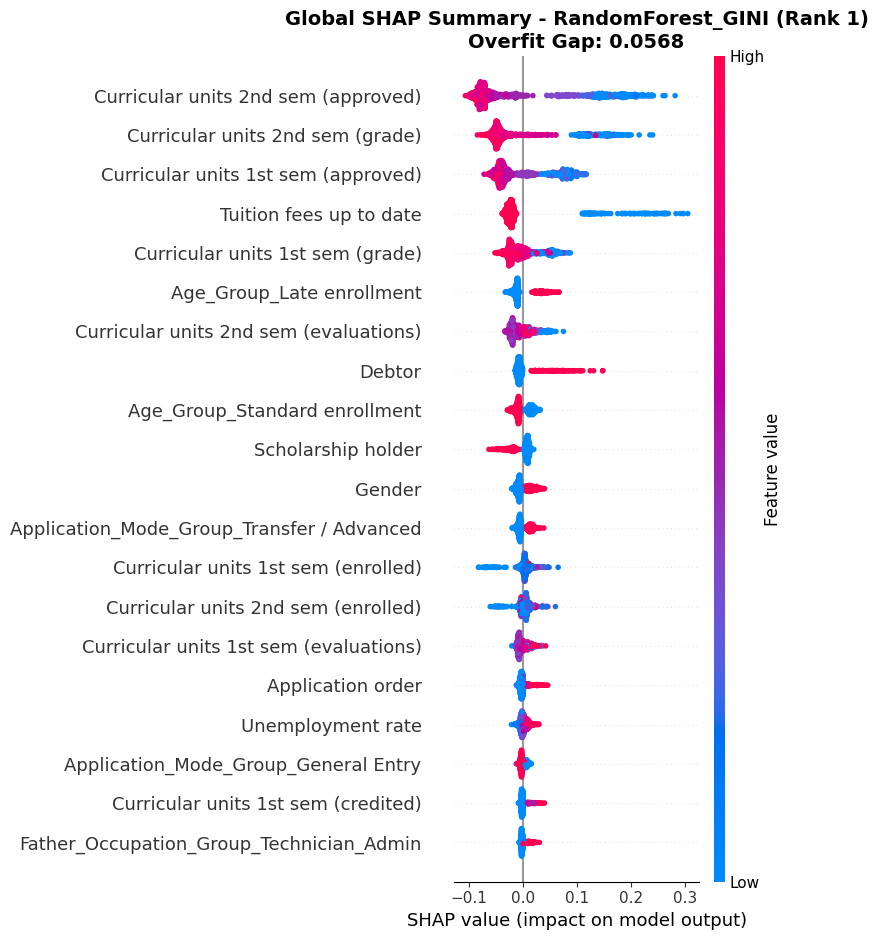


Generating Local SHAP Waterfall Plots for RandomForest_GINI...

  [Most Confident] Test Index: 23
    Actual Label:     1
    Predicted Label:  1 (threshold=0.140)
    Predicted Prob:   0.6025
    SHAP f(x):        0.6025
    Prediction:       ✓ CORRECT


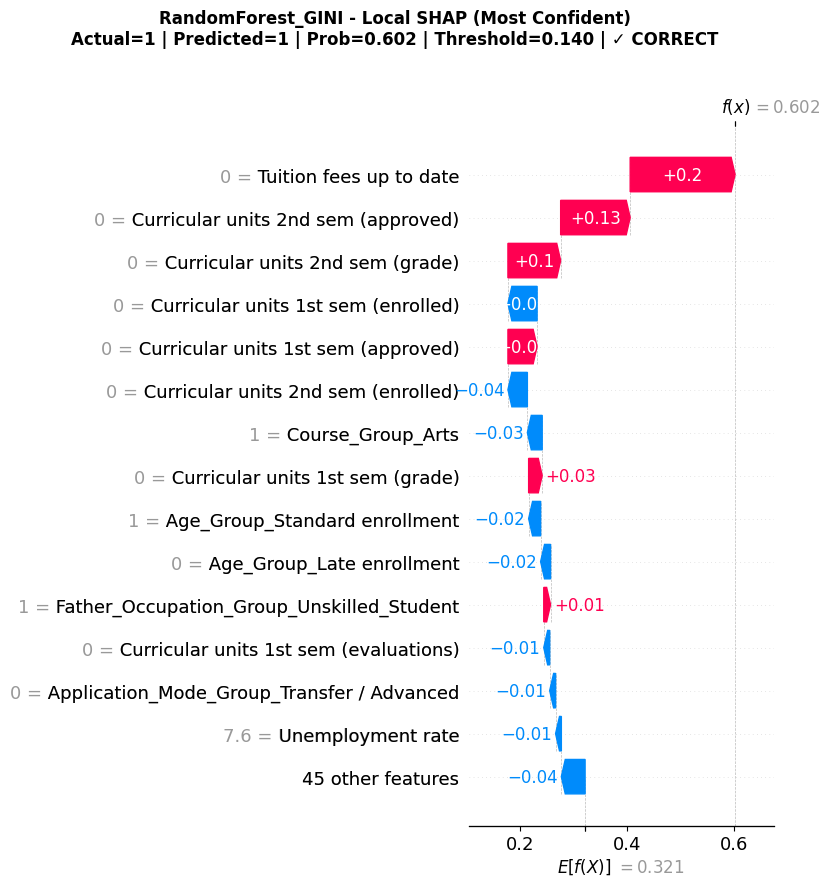


  [Median Case] Test Index: 391
    Actual Label:     0
    Predicted Label:  1 (threshold=0.140)
    Predicted Prob:   0.1472
    SHAP f(x):        0.1472
    Prediction:       ✗ WRONG


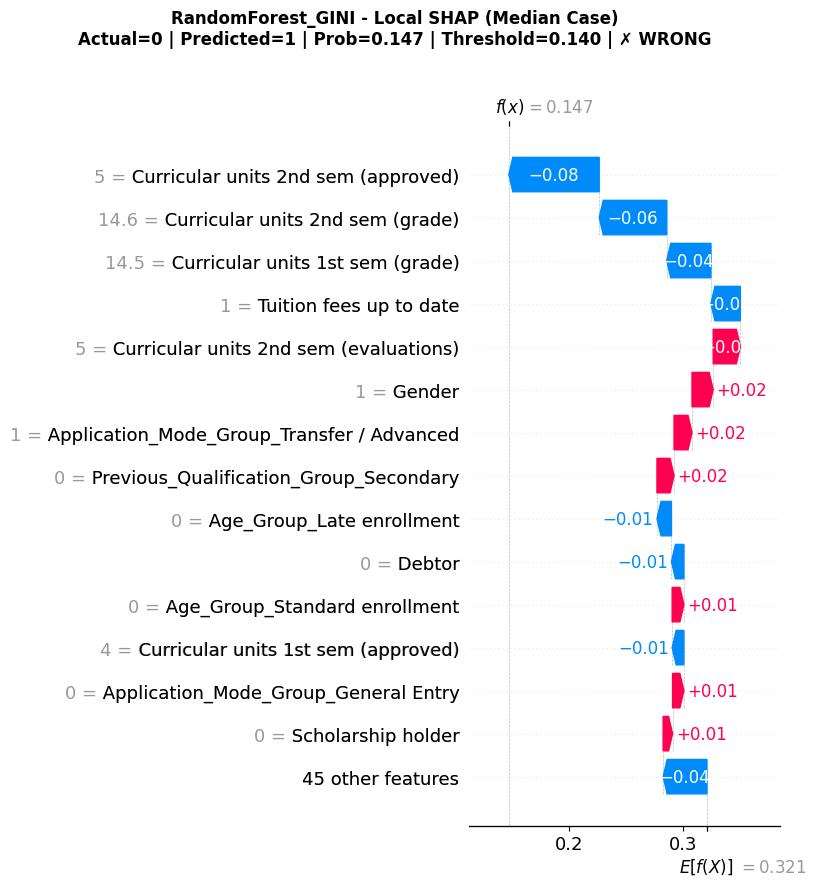


  [Most Confusing] Test Index: 19
    Actual Label:     0
    Predicted Label:  1 (threshold=0.140)
    Predicted Prob:   0.1625
    SHAP f(x):        0.1625
    Prediction:       ✗ WRONG


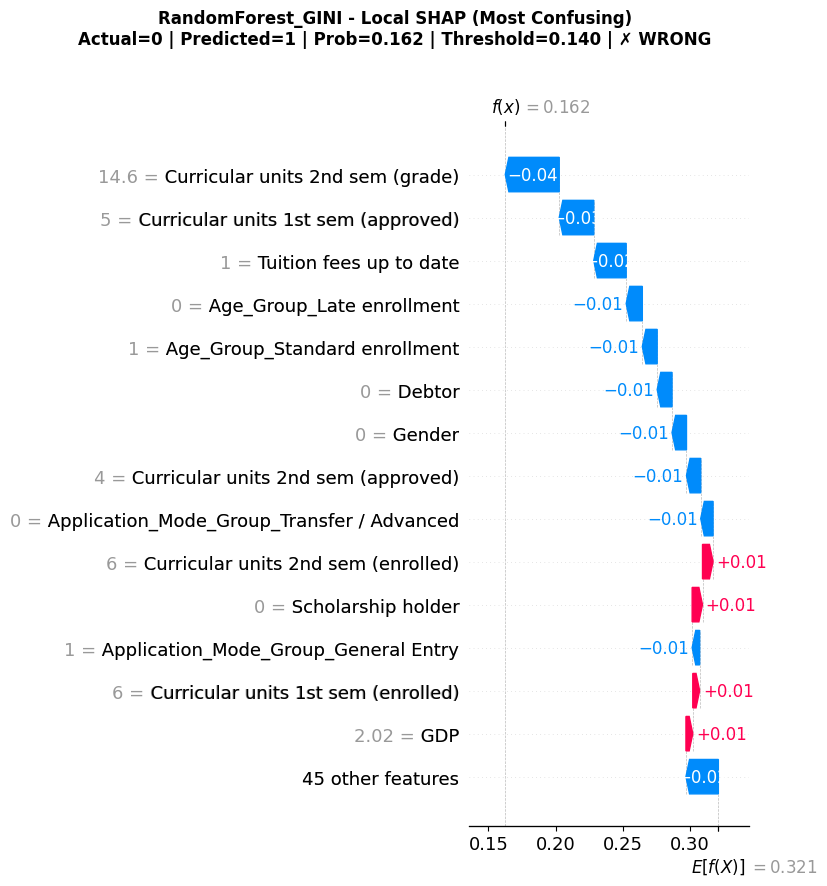


################################################################################
RANK 2: XGBoost_Logistic
CV Custom Loss: -71,750 | Test Custom Loss: -71,500
CV Overfit Gap: 0.0706 | Test Overfit Gap: 0.0552
################################################################################

Best Hyperparameters (from Grid Search):
  learning_rate: 0.1
  max_depth: 5
  n_estimators: 100

Top 20 Features by SHAP Importance:
                               Feature  SHAP_Importance
   Curricular units 2nd sem (approved)         1.387262
               Tuition fees up to date         0.498671
   Curricular units 1st sem (approved)         0.285907
   Curricular units 2nd sem (enrolled)         0.225135
Curricular units 2nd sem (evaluations)         0.177839
             Age_Group_Late enrollment         0.165729
   Curricular units 1st sem (enrolled)         0.160678
      Curricular units 2nd sem (grade)         0.152474
                    Scholarship holder         0.136076
      Curricula

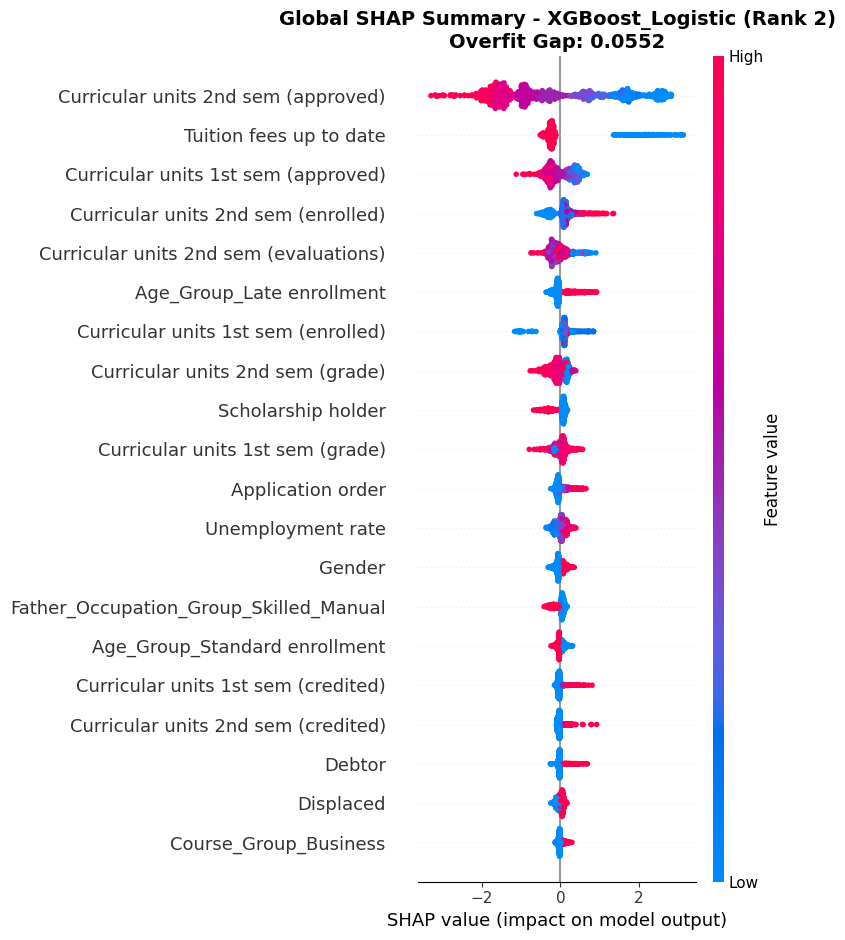


Generating Local SHAP Waterfall Plots for XGBoost_Logistic...

  [Most Confident] Test Index: 621
    Actual Label:     0
    Predicted Label:  1 (threshold=0.115)
    Predicted Prob:   0.9587
    SHAP f(x):        3.1444
    Prediction:       ✗ WRONG


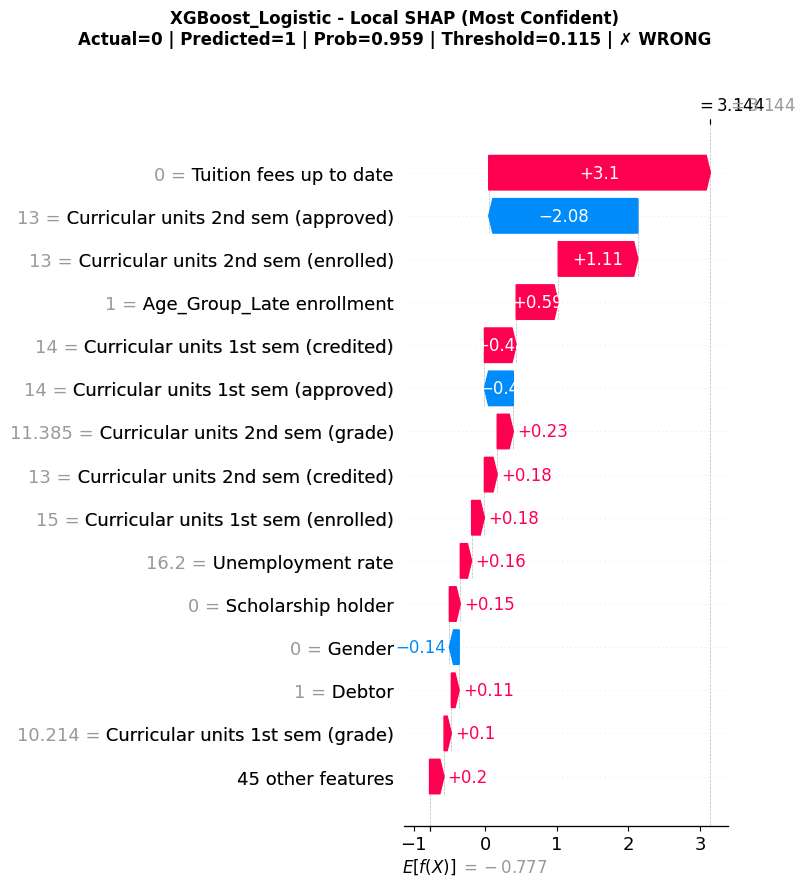


  [Median Case] Test Index: 364
    Actual Label:     0
    Predicted Label:  0 (threshold=0.115)
    Predicted Prob:   0.0499
    SHAP f(x):        -2.9476
    Prediction:       ✓ CORRECT


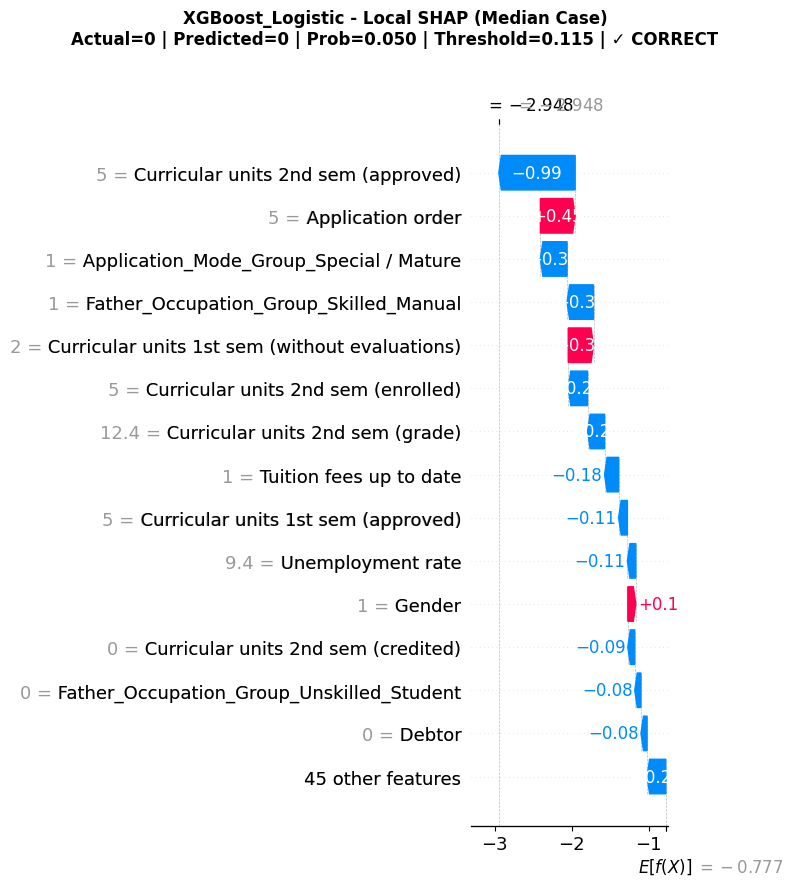


  [Most Confusing] Test Index: 865
    Actual Label:     0
    Predicted Label:  1 (threshold=0.115)
    Predicted Prob:   0.1916
    SHAP f(x):        -1.4397
    Prediction:       ✗ WRONG


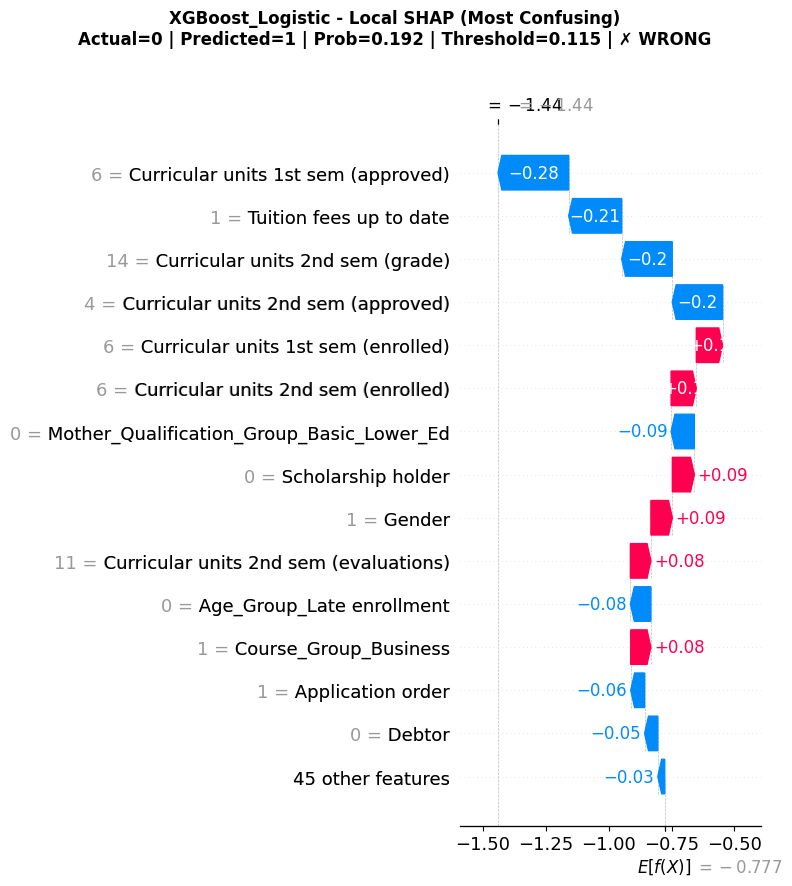


################################################################################
RANK 3: GradientBoosting_Deviance
CV Custom Loss: -66,125 | Test Custom Loss: -78,500
CV Overfit Gap: 0.0407 | Test Overfit Gap: 0.0201
################################################################################

Best Hyperparameters (from Grid Search):
  learning_rate: 0.1
  max_depth: 3
  n_estimators: 100

Top 20 Features by SHAP Importance:
                                       Feature  SHAP_Importance
           Curricular units 2nd sem (approved)         1.174915
                       Tuition fees up to date         0.418496
           Curricular units 1st sem (approved)         0.263585
           Curricular units 2nd sem (enrolled)         0.234975
              Curricular units 2nd sem (grade)         0.182906
                     Age_Group_Late enrollment         0.156082
                            Scholarship holder         0.136520
        Curricular units 2nd sem (evaluations)        

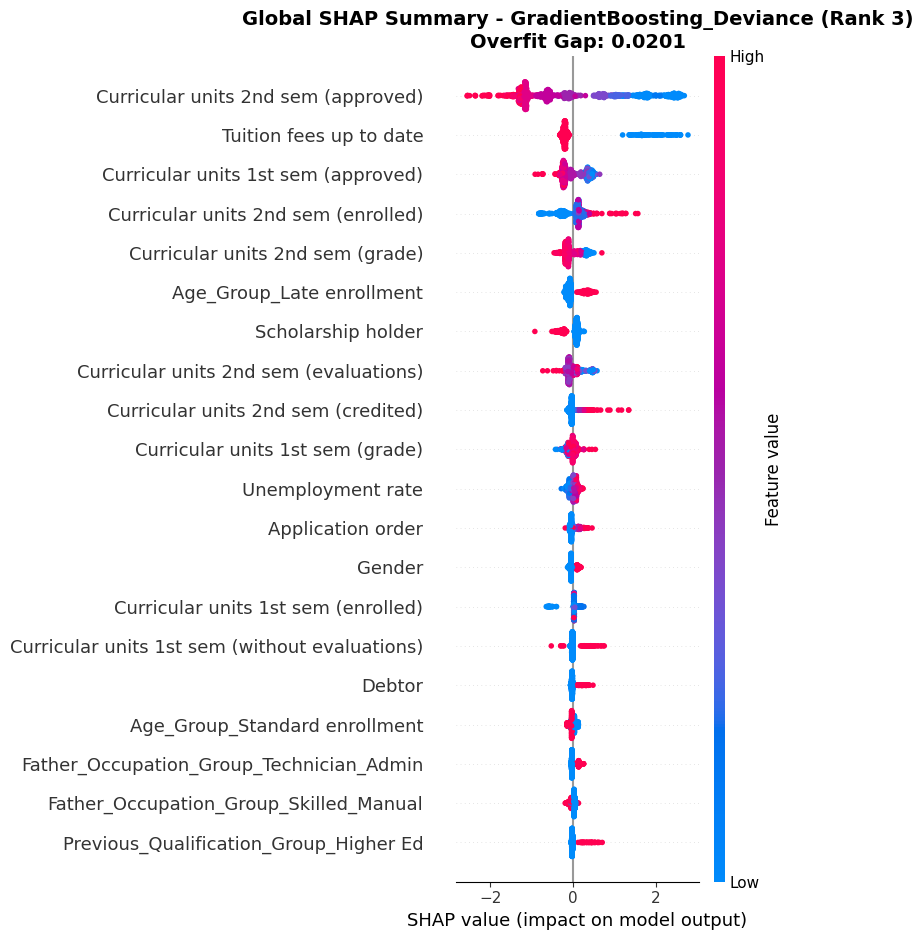


Generating Local SHAP Waterfall Plots for GradientBoosting_Deviance...

  [Most Confident] Test Index: 621
    Actual Label:     0
    Predicted Label:  1 (threshold=0.113)
    Predicted Prob:   0.8501
    SHAP f(x):        1.7350
    Prediction:       ✗ WRONG


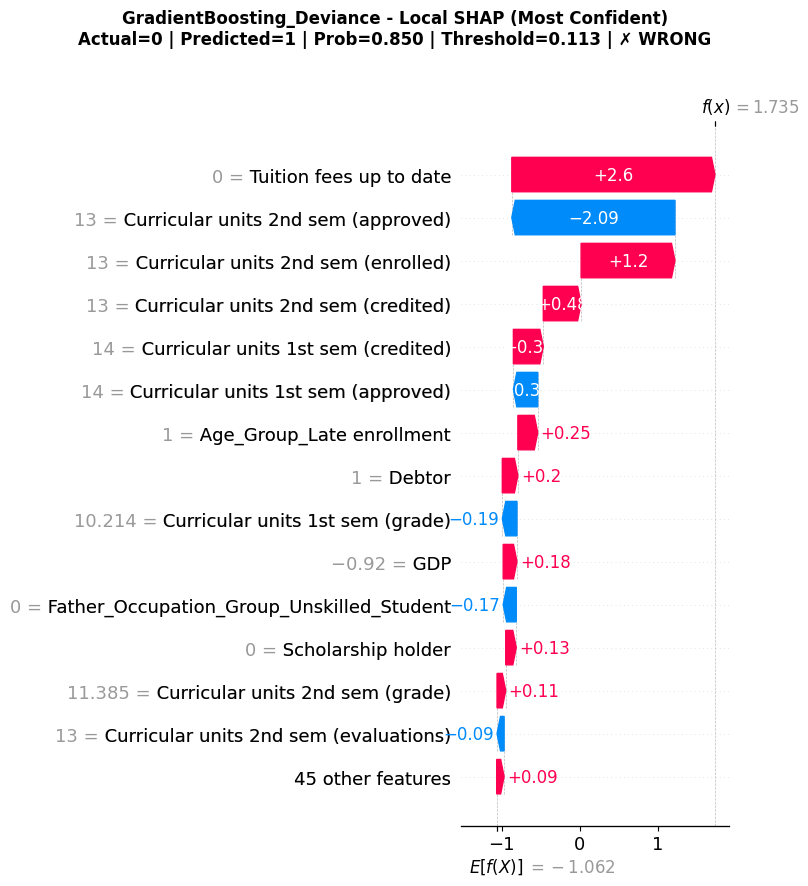


  [Median Case] Test Index: 883
    Actual Label:     0
    Predicted Label:  0 (threshold=0.113)
    Predicted Prob:   0.0422
    SHAP f(x):        -3.1225
    Prediction:       ✓ CORRECT


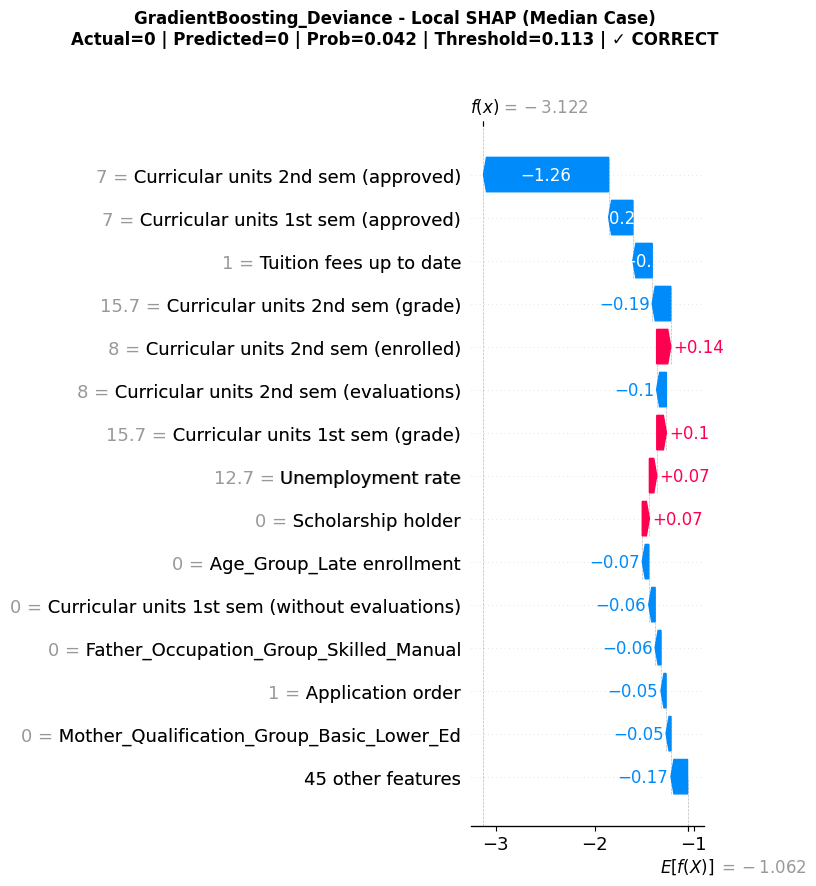


  [Most Confusing] Test Index: 19
    Actual Label:     0
    Predicted Label:  1 (threshold=0.113)
    Predicted Prob:   0.1647
    SHAP f(x):        -1.6238
    Prediction:       ✗ WRONG


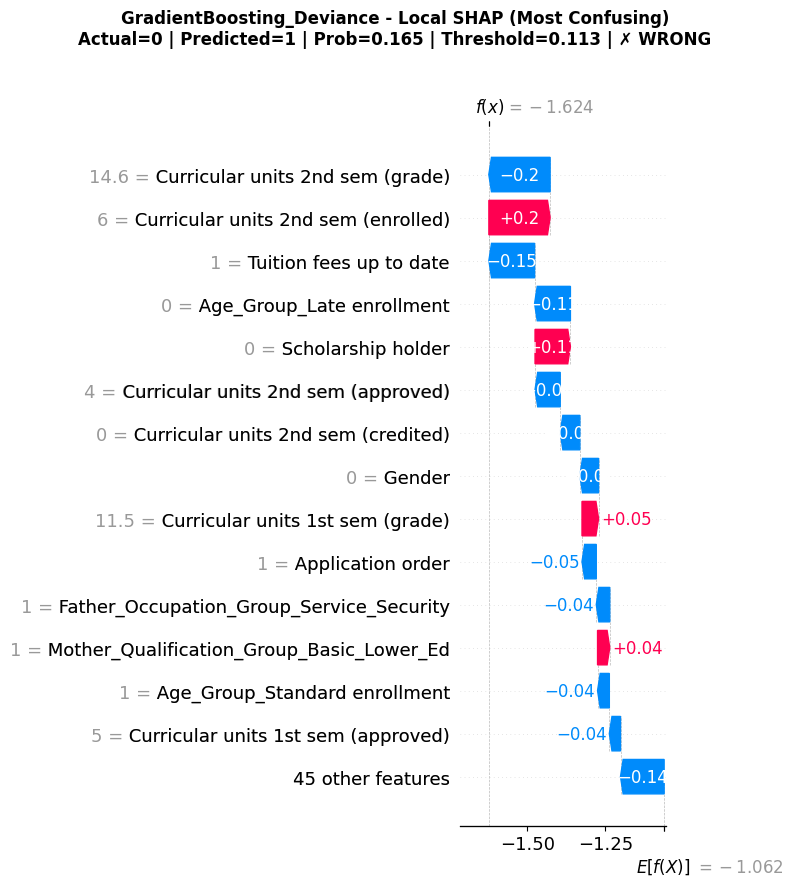


################################################################################
RANK 4: RandomForest_L2
CV Custom Loss: -64,750 | Test Custom Loss: -53,000
CV Overfit Gap: 0.0247 | Test Overfit Gap: 0.0132
################################################################################

Best Hyperparameters (from Grid Search):
  max_depth: 5
  min_samples_split: 10
  n_estimators: 100

Actual Tree Depth Statistics:
  Average depth: 5.00
  Min depth: 5
  Max depth: 5
  Median depth: 5.0

Top 20 Features by SHAP Importance:
                                   Feature  SHAP_Importance
       Curricular units 2nd sem (approved)         0.228950
                   Tuition fees up to date         0.069167
          Curricular units 2nd sem (grade)         0.019111
       Curricular units 1st sem (enrolled)         0.012996
       Curricular units 2nd sem (enrolled)         0.011795
                 Age_Group_Late enrollment         0.010525
    Curricular units 2nd sem (evaluations)        

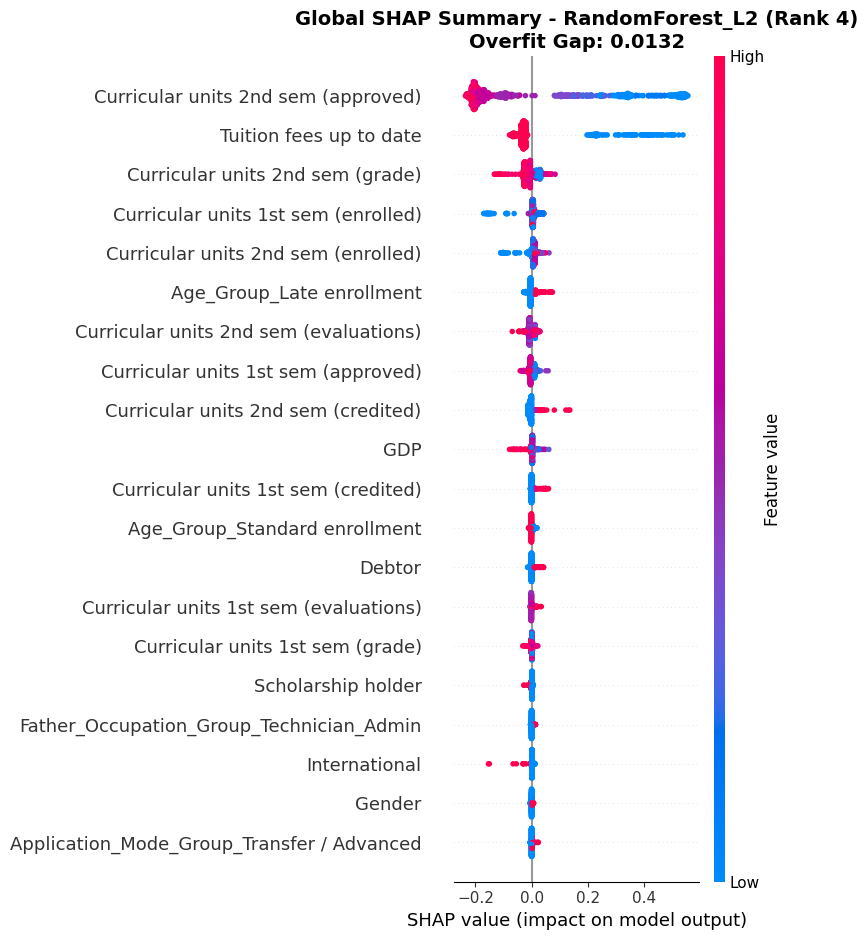


Generating Local SHAP Waterfall Plots for RandomForest_L2...

  [Most Confident] Test Index: 168
    Actual Label:     1
    Predicted Label:  1 (threshold=0.115)
    Predicted Prob:   0.7588
    SHAP f(x):        0.7588
    Prediction:       ✓ CORRECT


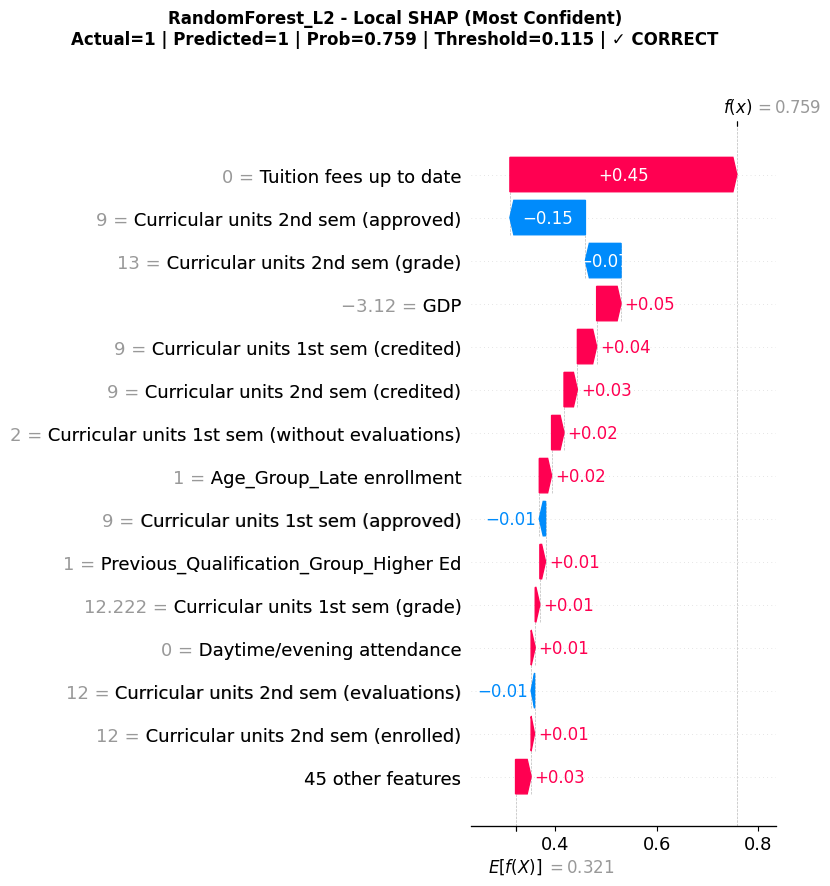


  [Median Case] Test Index: 187
    Actual Label:     0
    Predicted Label:  0 (threshold=0.115)
    Predicted Prob:   0.0565
    SHAP f(x):        0.0565
    Prediction:       ✓ CORRECT


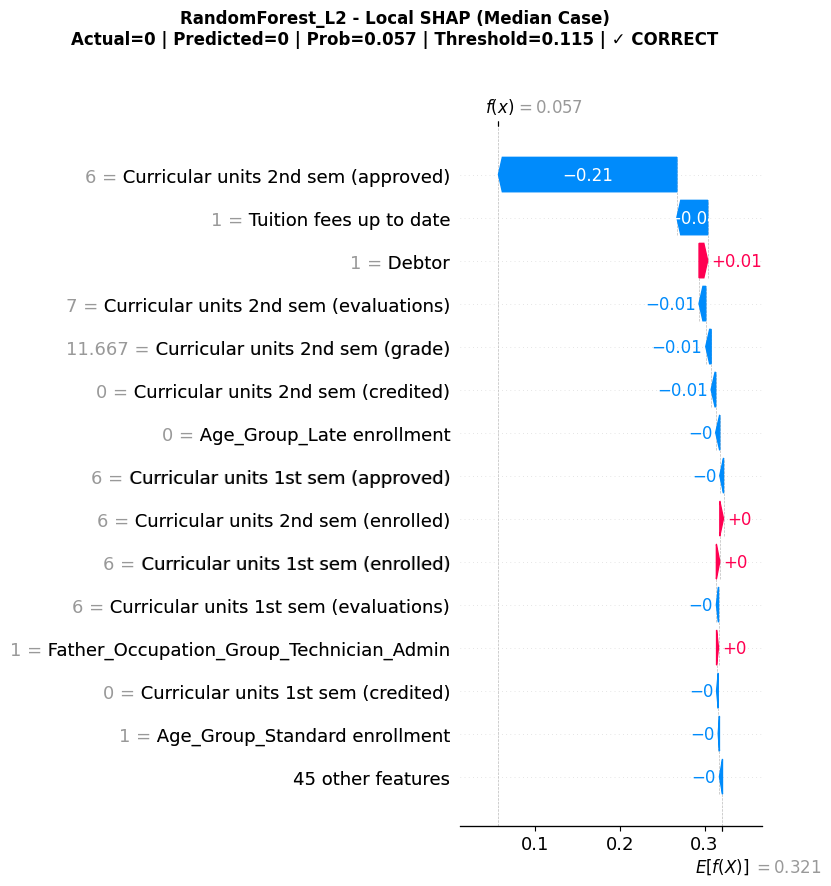


  [Most Confusing] Test Index: 447
    Actual Label:     0
    Predicted Label:  1 (threshold=0.115)
    Predicted Prob:   0.2162
    SHAP f(x):        0.2162
    Prediction:       ✗ WRONG


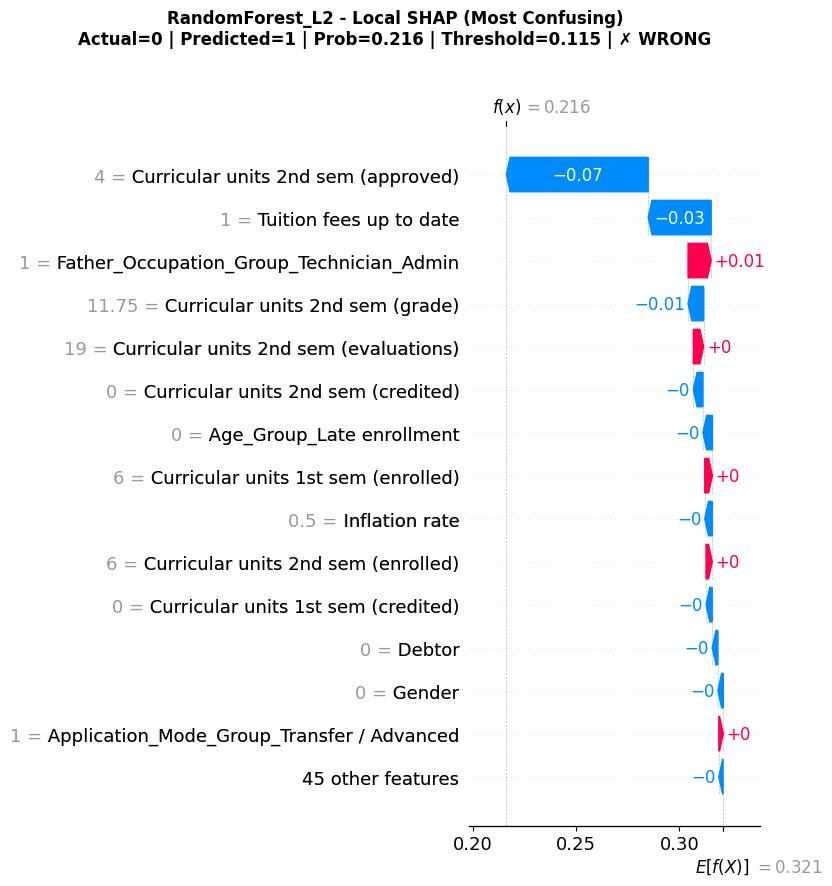


################################################################################
RANK 5: GradientBoosting_L2
CV Custom Loss: -52,750 | Test Custom Loss: -45,000
CV Overfit Gap: 0.0082 | Test Overfit Gap: -0.0030
################################################################################

Best Hyperparameters (from Grid Search):
  learning_rate: 0.01
  max_depth: 3
  n_estimators: 100

Top 20 Features by SHAP Importance:
                               Feature  SHAP_Importance
   Curricular units 2nd sem (approved)         0.148989
               Tuition fees up to date         0.043851
             Age_Group_Late enrollment         0.009081
      Curricular units 2nd sem (grade)         0.007114
   Curricular units 2nd sem (enrolled)         0.006069
Curricular units 2nd sem (evaluations)         0.005678
   Curricular units 1st sem (enrolled)         0.004727
                                   GDP         0.001899
   Curricular units 1st sem (credited)         0.001647
   Curricu

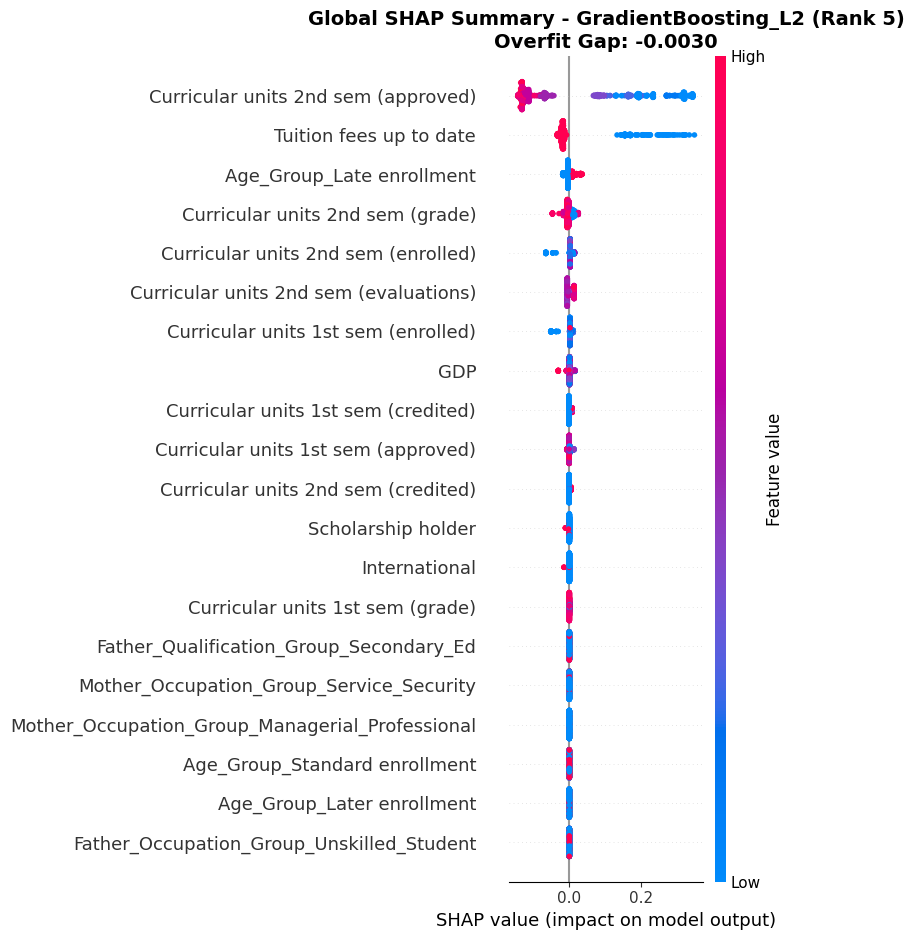


Generating Local SHAP Waterfall Plots for GradientBoosting_L2...

  [Most Confident] Test Index: 136
    Actual Label:     0
    Predicted Label:  1 (threshold=0.177)
    Predicted Prob:   0.6403
    SHAP f(x):        0.6403
    Prediction:       ✗ WRONG


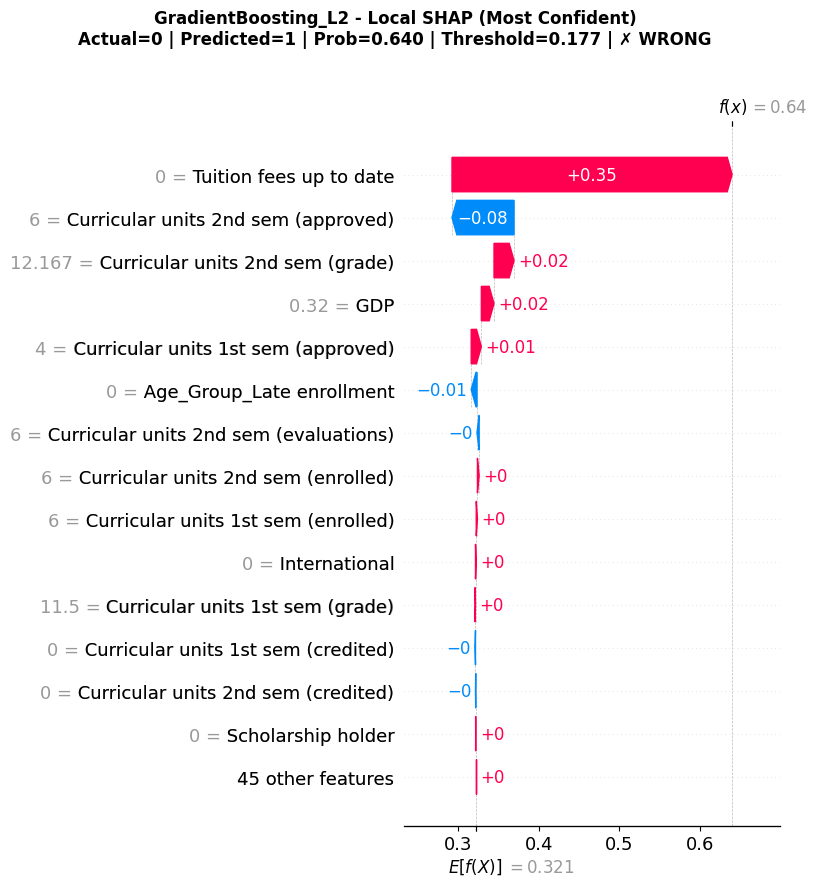


  [Median Case] Test Index: 186
    Actual Label:     0
    Predicted Label:  0 (threshold=0.177)
    Predicted Prob:   0.1597
    SHAP f(x):        0.1597
    Prediction:       ✓ CORRECT


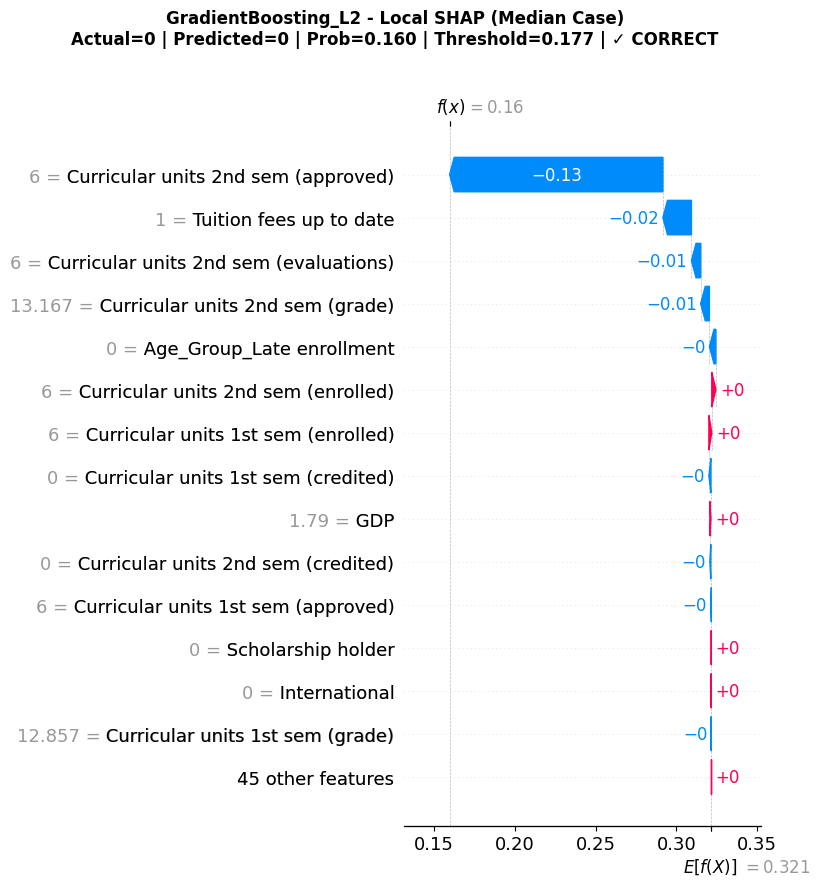


  [Most Confusing] Test Index: 403
    Actual Label:     0
    Predicted Label:  1 (threshold=0.177)
    Predicted Prob:   0.2265
    SHAP f(x):        0.2265
    Prediction:       ✗ WRONG


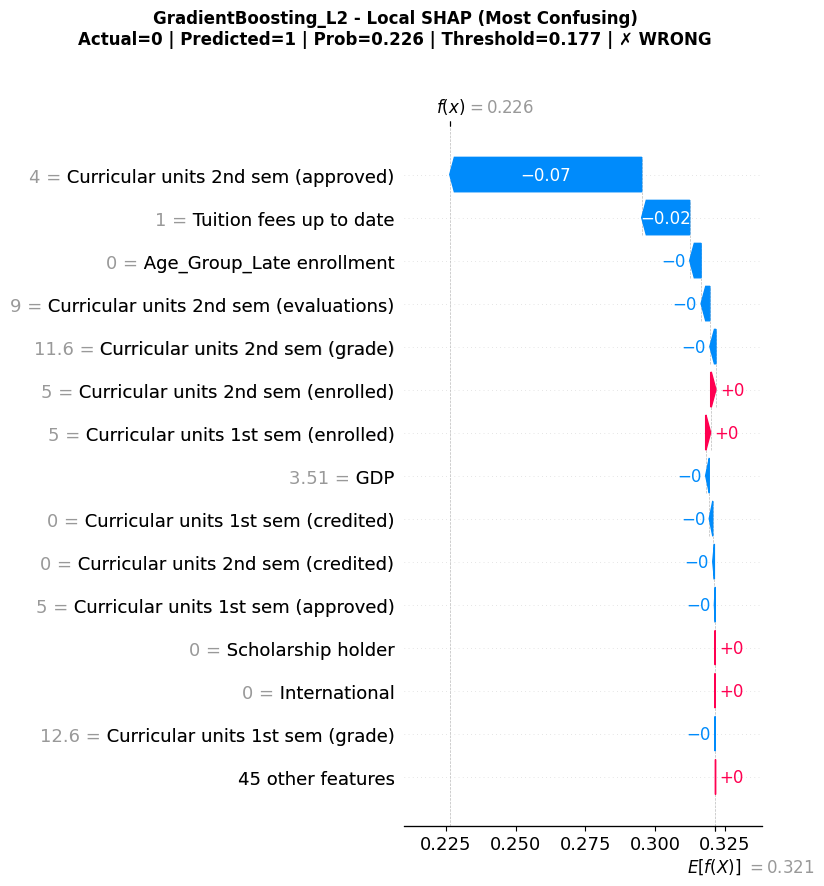


################################################################################
RANK 6: XGBoost_L2
CV Custom Loss: 142,375 | Test Custom Loss: 121,500
CV Overfit Gap: 0.0527 | Test Overfit Gap: 0.0335
################################################################################

Best Hyperparameters (from Grid Search):
  learning_rate: 0.1
  max_depth: 3
  n_estimators: 200

Top 20 Features by SHAP Importance:
                                       Feature  SHAP_Importance
           Curricular units 2nd sem (approved)         0.215268
                       Tuition fees up to date         0.064424
           Curricular units 1st sem (approved)         0.042713
           Curricular units 2nd sem (enrolled)         0.041287
              Curricular units 2nd sem (grade)         0.024612
                     Age_Group_Late enrollment         0.019917
           Curricular units 1st sem (enrolled)         0.018846
              Curricular units 1st sem (grade)         0.017161
     

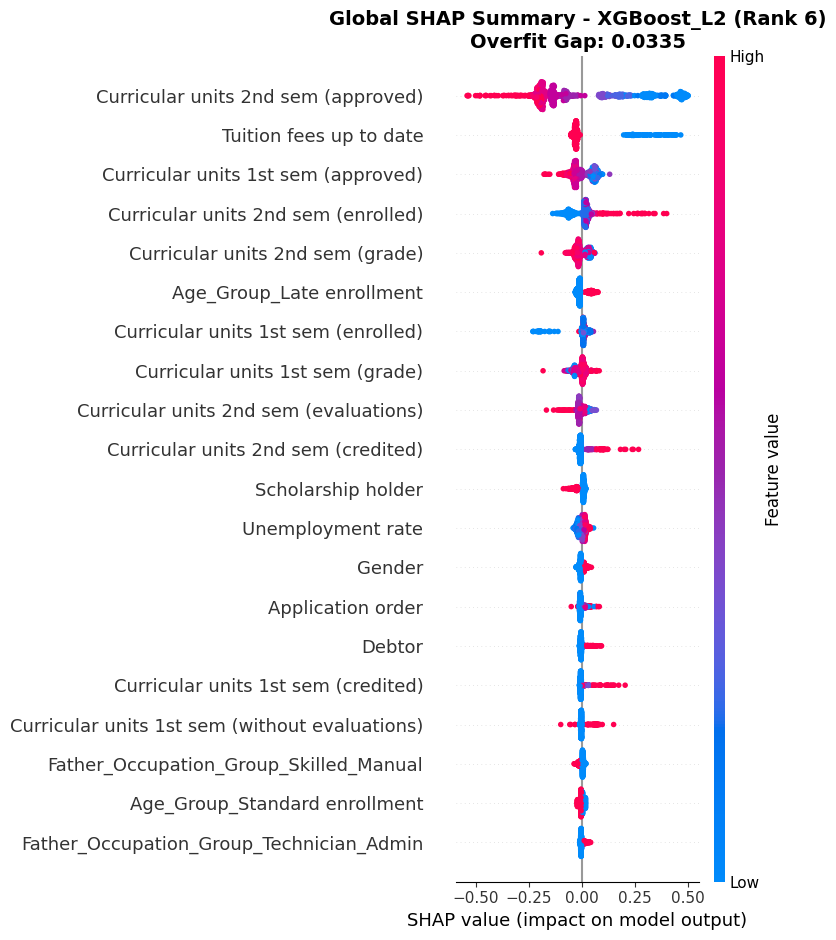


Generating Local SHAP Waterfall Plots for XGBoost_L2...

  [Most Confident] Test Index: 621
    Actual Label:     0
    Predicted Label:  1 (threshold=0.100)
    Predicted Prob:   1.0000
    SHAP f(x):        0.7860
    Prediction:       ✗ WRONG


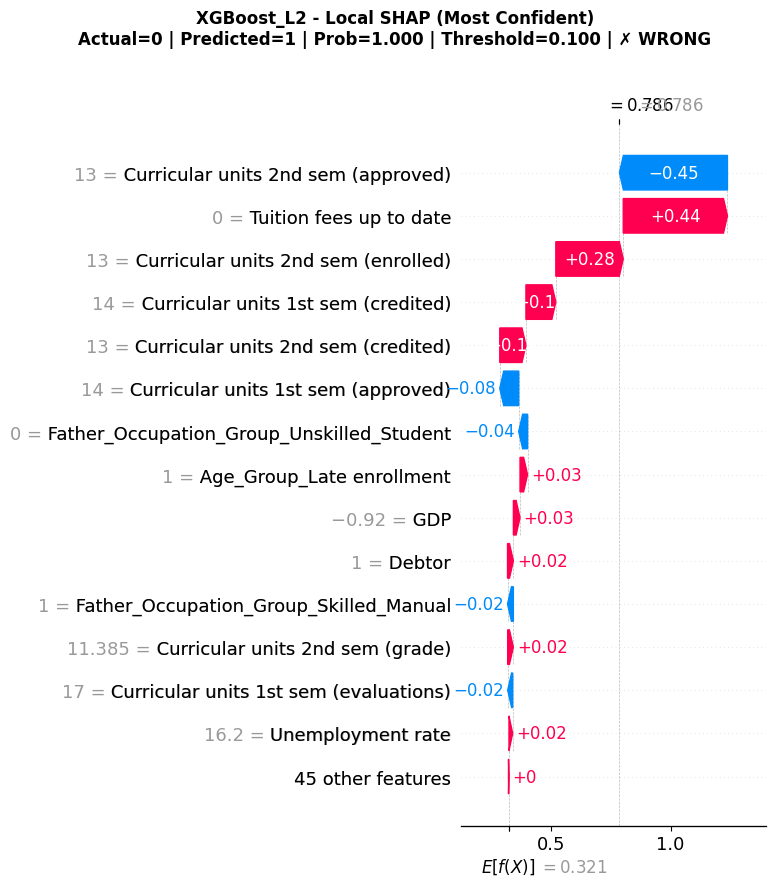


  [Median Case] Test Index: 139
    Actual Label:     0
    Predicted Label:  0 (threshold=0.100)
    Predicted Prob:   0.0000
    SHAP f(x):        -0.0096
    Prediction:       ✓ CORRECT


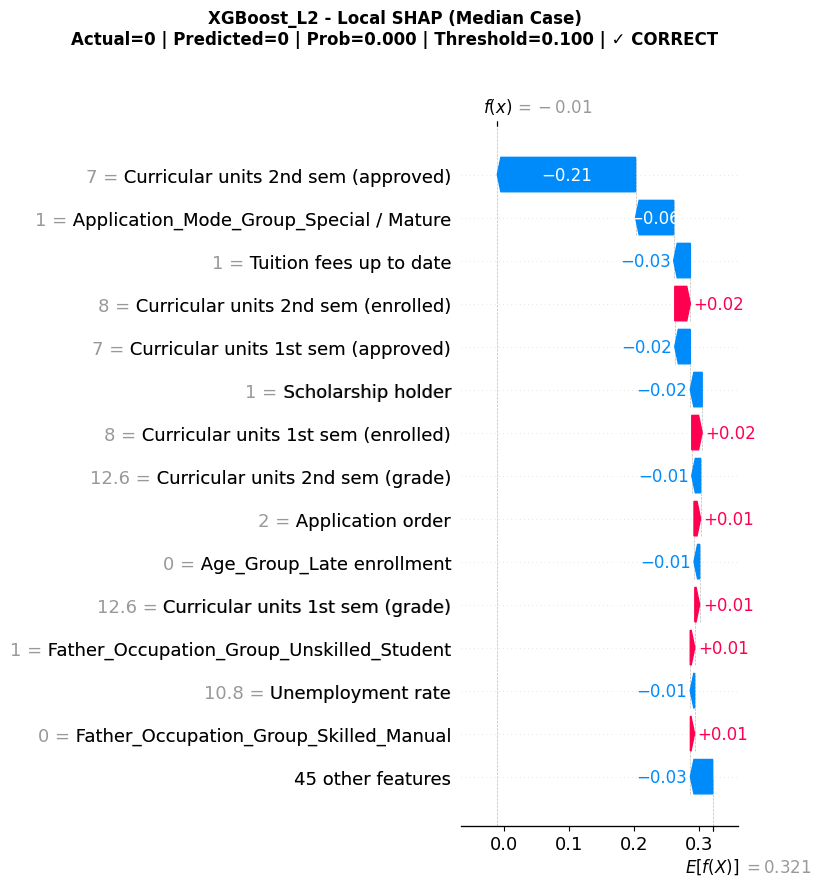


  [Most Confusing] Test Index: 214
    Actual Label:     0
    Predicted Label:  0 (threshold=0.100)
    Predicted Prob:   0.0000
    SHAP f(x):        0.1829
    Prediction:       ✓ CORRECT


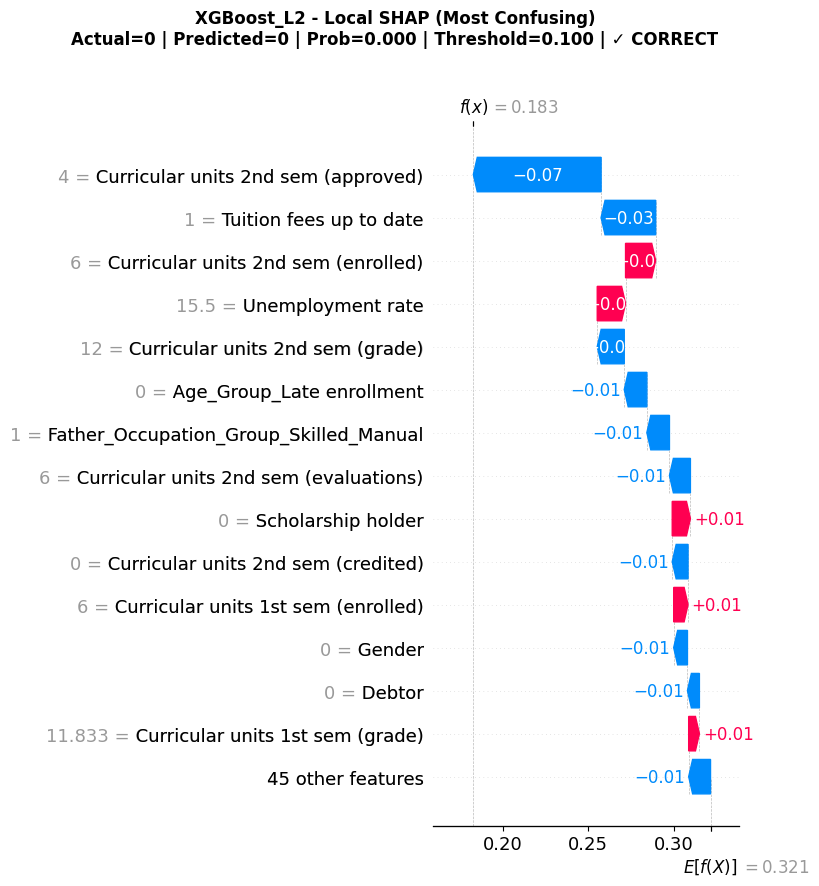


SHAP ANALYSIS COMPLETED


In [ ]:
print(f"\n{'='*80}")
print("INTERPRETATION OF ALL BLACKBOX MODELS (RANKED BY CV CUSTOM LOSS)")
print('='*80)

# Sort blackbox models by CV custom loss
sorted_blackbox = sorted(results_blackbox.items(), key=lambda x: x[1]['cv_loss'])

# Get feature names once
onehot_cols = list(sorted_blackbox[0][1]['model'].named_steps['preprocessor']
                   .named_transformers_['cat'].get_feature_names_out(categorical_cols))
shap_feature_names = numeric_cols + onehot_cols

for rank, (name, results) in enumerate(sorted_blackbox, 1):
    print(f"\n{'#'*80}")
    print(f"RANK {rank}: {name}")
    print(f"CV Custom Loss: {results['cv_loss']:,.0f} | Test Custom Loss: {results['test_loss']:,.0f}")
    print(f"CV Overfit Gap: {results['cv_overfit_gap']:.4f} | Test Overfit Gap: {results['test_overfit_gap']:.4f}")
    print('#'*80)
    #Overfitting Gap = Train AUC - Validation AUC (> 0.05 Significant overfitting)
    
    # Display best parameters
    print("\nBest Hyperparameters (from Grid Search):")
    params = results['params']
    for param, value in params.items():
        print(f"  {param}: {value}")
    
    # Tree depth info
    if results.get('tree_depths'):
        depths = results['tree_depths']
        print(f"\nActual Tree Depth Statistics:")
        print(f"  Average depth: {np.mean(depths):.2f}")
        print(f"  Min depth: {np.min(depths)}")
        print(f"  Max depth: {np.max(depths)}")
        print(f"  Median depth: {np.median(depths):.1f}")
    
    # Get transformed test data
    X_test_transformed = results['model'].named_steps['preprocessor'].transform(X_test)
    
    # Get predictions
    y_test_scores = results['y_test_scores']
    threshold = results['threshold']
    y_test_pred = (y_test_scores >= threshold).astype(int)
    y_test_true = y_test.values if hasattr(y_test, 'values') else y_test
    
    # Create SHAP explainer
    classifier = results['model'].named_steps['classifier']
    
    try:
        explainer = shap.TreeExplainer(classifier)
        shap_values = explainer.shap_values(X_test_transformed)
        
        # Handle different SHAP output formats
        if isinstance(shap_values, list):
            shap_values = shap_values[1]  # Positive class
        elif len(shap_values.shape) == 3:
            shap_values = shap_values[:, :, 1]  # Positive class
        
        # Feature importance
        shap_importance = pd.DataFrame({
            'Feature': shap_feature_names,
            'SHAP_Importance': np.abs(shap_values).mean(axis=0)
        }).sort_values('SHAP_Importance', ascending=False)
        
        print("\nTop 20 Features by SHAP Importance:")
        print(shap_importance.head(20).to_string(index=False))
        
        # SHAP summary plot
        print(f"\nGenerating SHAP Summary Plot for {name}...")
        plt.figure(figsize=(10, 8))
        shap.summary_plot(shap_values, X_test_transformed, 
                         feature_names=shap_feature_names, 
                         max_display=20, show=False)
        plt.title(f'Global SHAP Summary - {name} (Rank {rank})\n'
                 f'Overfit Gap: {results["test_overfit_gap"]:.4f}', 
                 fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

        # ===== LOCAL SHAP: Pick 3 representative samples =====
        print(f"\nGenerating Local SHAP Waterfall Plots for {name}...")

        # Select representative instances
        shap_strength = np.abs(shap_values).sum(axis=1)
        idx_best = np.argsort(shap_strength)[-1]     # strongest explanation
        idx_mid  = np.argsort(shap_strength)[len(shap_strength)//2]  # median
        idx_weak = np.argsort(shap_strength)[0]      # weakest

        selected_indices = [idx_best, idx_mid, idx_weak]
        labels = ["Most Confident", "Median Case", "Most Confusing"]

        # Get base value
        base_value = explainer.expected_value
        if isinstance(base_value, (list, np.ndarray)):
            base_value = base_value[1] if len(base_value) > 1 else base_value[0]

        for label, idx in zip(labels, selected_indices):
            # Get prediction details
            y_true = y_test_true[idx]
            y_prob = y_test_scores[idx]
            y_pred = y_test_pred[idx]
            fx = base_value + shap_values[idx].sum()
            
            # Print details
            print(f"\n  [{label}] Test Index: {idx}")
            print(f"    Actual Label:     {y_true}")
            print(f"    Predicted Label:  {y_pred} (threshold={threshold:.3f})")
            print(f"    Predicted Prob:   {y_prob:.4f}")
            print(f"    SHAP f(x):        {fx:.4f}")
            print(f"    Prediction:       {'✓ CORRECT' if y_true == y_pred else '✗ WRONG'}")
            
            # Create waterfall plot
            plt.figure(figsize=(10, 7))
            shap.waterfall_plot(
                shap.Explanation(
                    values=shap_values[idx],
                    base_values=base_value,
                    data=X_test_transformed[idx],
                    feature_names=shap_feature_names
                ),
                max_display=15,
                show=False
            )
            
            # Add detailed title
            fig = plt.gcf()
            correctness = '✓ CORRECT' if y_true == y_pred else '✗ WRONG'
            title = (f"{name} - Local SHAP ({label})\n"
                     f"Actual={y_true} | Predicted={y_pred} | Prob={y_prob:.3f} | "
                     f"Threshold={threshold:.3f} | {correctness}")
            fig.suptitle(title, fontsize=12, fontweight='bold')
            fig.tight_layout(rect=[0, 0, 1, 0.96])
            plt.show()
        
    except Exception as e:
        print(f"\n⚠️  Could not generate SHAP values for {name}")
        print(f"   Error: {str(e)}")
        import traceback
        print(f"   Traceback:")
        traceback.print_exc()

print(f"\n{'='*80}")
print("SHAP ANALYSIS COMPLETED")
print('='*80)

## STEP 5: Conclusion & Comparison


STEP 5: FINAL MODEL COMPARISON AND SUMMARY

COMPLETE MODEL PERFORMANCE COMPARISON (Sorted by CV Custom Loss)
                    Model         Category Max_Depth Avg_Depth   CV_AUC  Test_AUC  Overfit_Gap  Threshold  Accuracy  Precision   Recall  F1_Score  CV_CustomLoss  Test_CustomLoss
        RandomForest_GINI     RandomForest        15      15.0 0.913598  0.929601     0.056783     0.1400  0.711864   0.528600 0.943662  0.677623       -81250.0           -84500
         XGBoost_Logistic          XGBoost         5       N/A 0.914186  0.925125     0.055178     0.1150  0.753672   0.572368 0.919014  0.705405       -71750.0           -71500
GradientBoosting_Deviance GradientBoosting         3       N/A 0.910799  0.926314     0.020092     0.1125  0.738983   0.555789 0.929577  0.695652       -66125.0           -78500
          RandomForest_L2     RandomForest         5       5.0 0.906164  0.914954     0.013168     0.1150  0.732203   0.549894 0.911972  0.686093       -64750.0           -53000


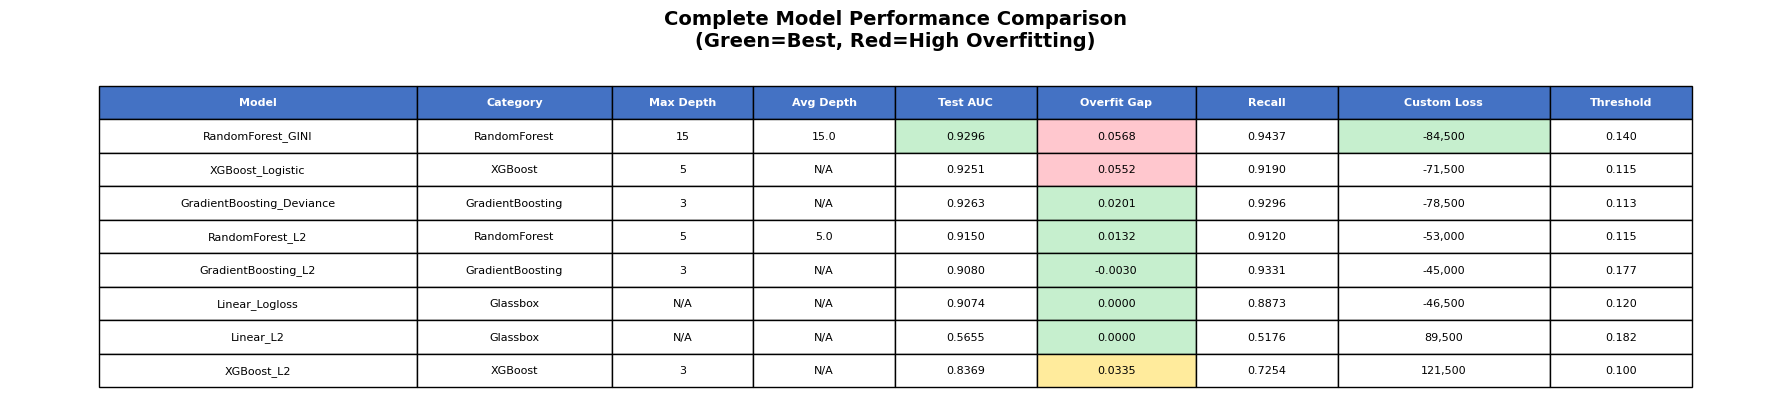


BEST MODEL FROM EACH CATEGORY
        Category                     Model  CV_CustomLoss  Test_CustomLoss  Test_AUC
        Glassbox            Linear_Logloss       -30125.0           -46500  0.907379
GradientBoosting GradientBoosting_Deviance       -66125.0           -78500  0.926314
    RandomForest         RandomForest_GINI       -81250.0           -84500  0.929601
         XGBoost          XGBoost_Logistic       -71750.0           -71500  0.925125


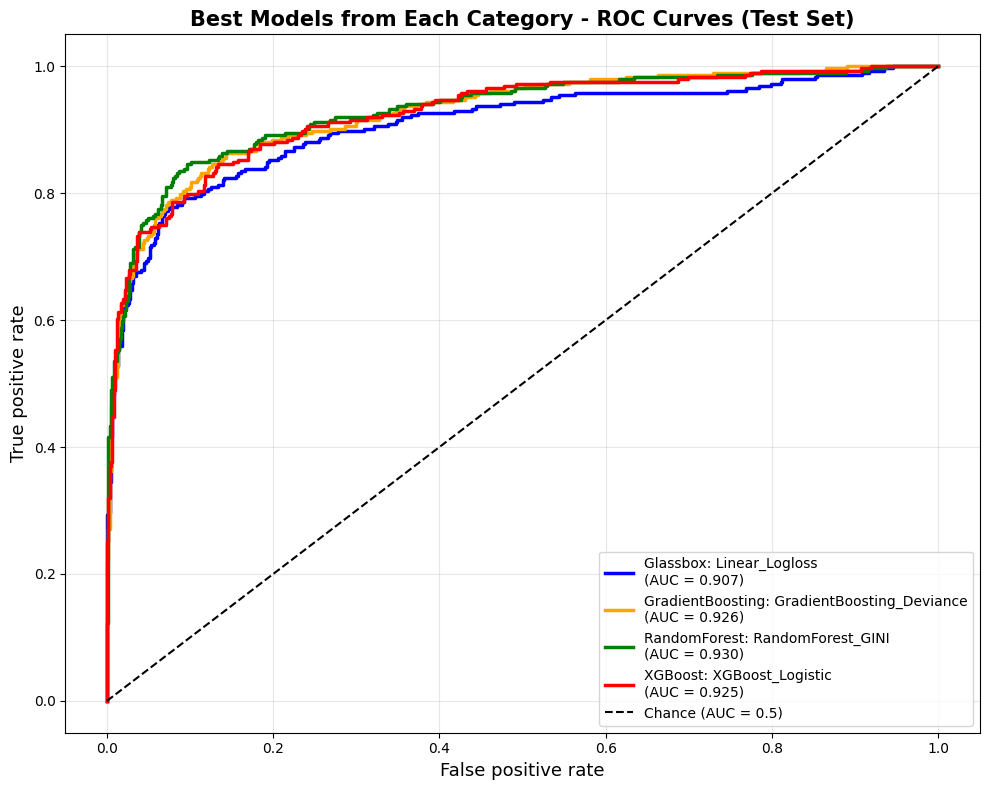


DETAILED TEST METRICS - BEST MODELS FROM EACH CATEGORY

Linear_Logloss
Threshold: 0.120
Test AUC: 0.9074
Accuracy: 0.7887
Precision: 0.6192
Recall (Sensitivity): 0.8873
F1 Score: 0.7294
Custom Loss: -46,500

Test Confusion Matrix:
              Predicted
               0      1
Actual 0    446    155
Actual 1     32    252

Sensitivity (Recall): 0.8873
Specificity: 0.7421

GradientBoosting_Deviance
Threshold: 0.113
Test AUC: 0.9263
Accuracy: 0.7390
Precision: 0.5558
Recall (Sensitivity): 0.9296
F1 Score: 0.6957
Custom Loss: -78,500

Test Confusion Matrix:
              Predicted
               0      1
Actual 0    390    211
Actual 1     20    264

Sensitivity (Recall): 0.9296
Specificity: 0.6489

RandomForest_GINI
Threshold: 0.140
Test AUC: 0.9296
Accuracy: 0.7119
Precision: 0.5286
Recall (Sensitivity): 0.9437
F1 Score: 0.6776
Custom Loss: -84,500

Test Confusion Matrix:
              Predicted
               0      1
Actual 0    362    239
Actual 1     16    268

Sensitivity (Recall

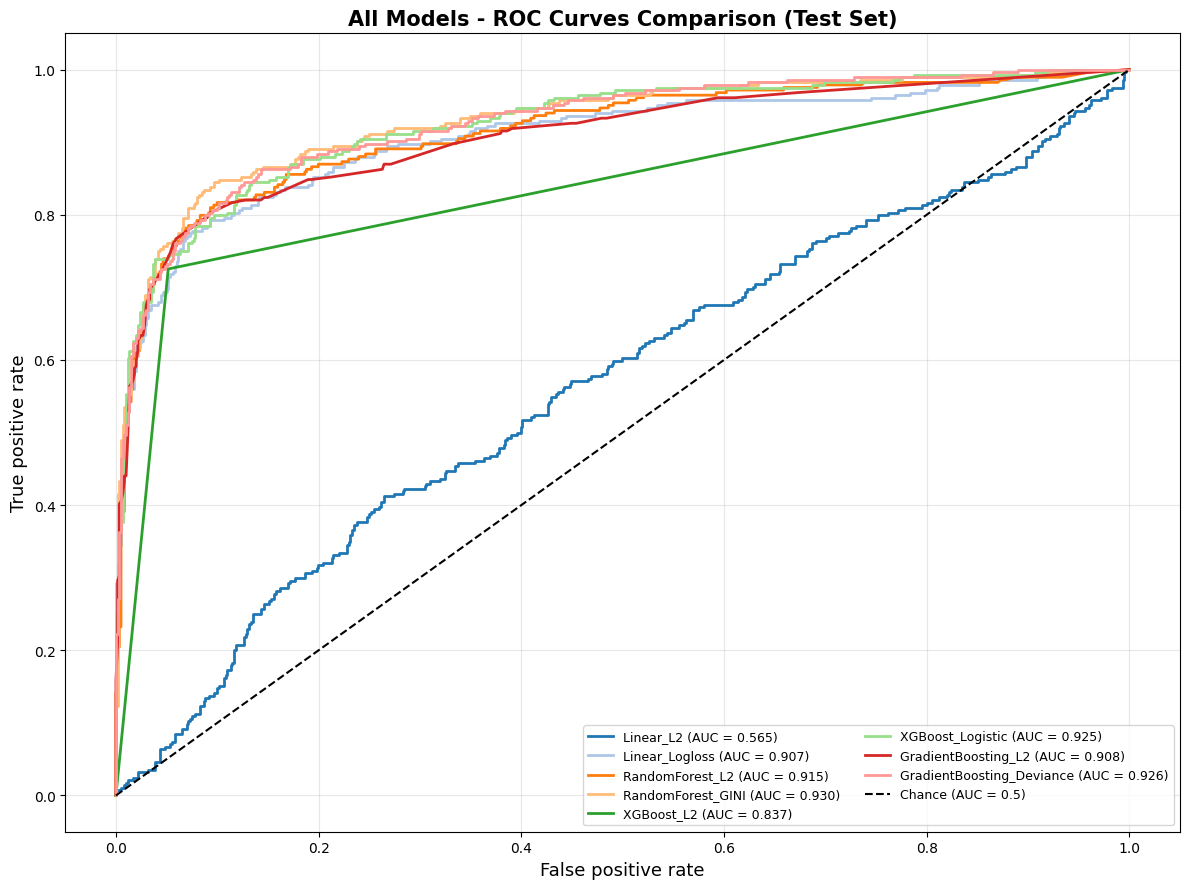


COMPREHENSIVE TEST METRICS - ALL MODELS


                    Model  Threshold  Test_AUC  Accuracy  Precision   Recall  Specificity  F1_Score  Test_CustomLoss
        RandomForest_GINI     0.1400  0.929601  0.711864   0.528600 0.943662     0.602329  0.677623           -84500
GradientBoosting_Deviance     0.1125  0.926314  0.738983   0.555789 0.929577     0.648918  0.695652           -78500
         XGBoost_Logistic     0.1150  0.925125  0.753672   0.572368 0.919014     0.675541  0.705405           -71500
          RandomForest_L2     0.1150  0.914954  0.732203   0.549894 0.911972     0.647255  0.686093           -53000
           Linear_Logloss     0.1200  0.907379  0.788701   0.619165 0.887324     0.742097  0.729378           -46500
      GradientBoosting_L2     0.1775  0.908029  0.653107   0.479204 0.933099     0.520799  0.633214           -45000
                Linear_L2     0.1825  0.565484  0.570621   0.376923 0.517606     0.595674  0.436202            89500
               XGBoos

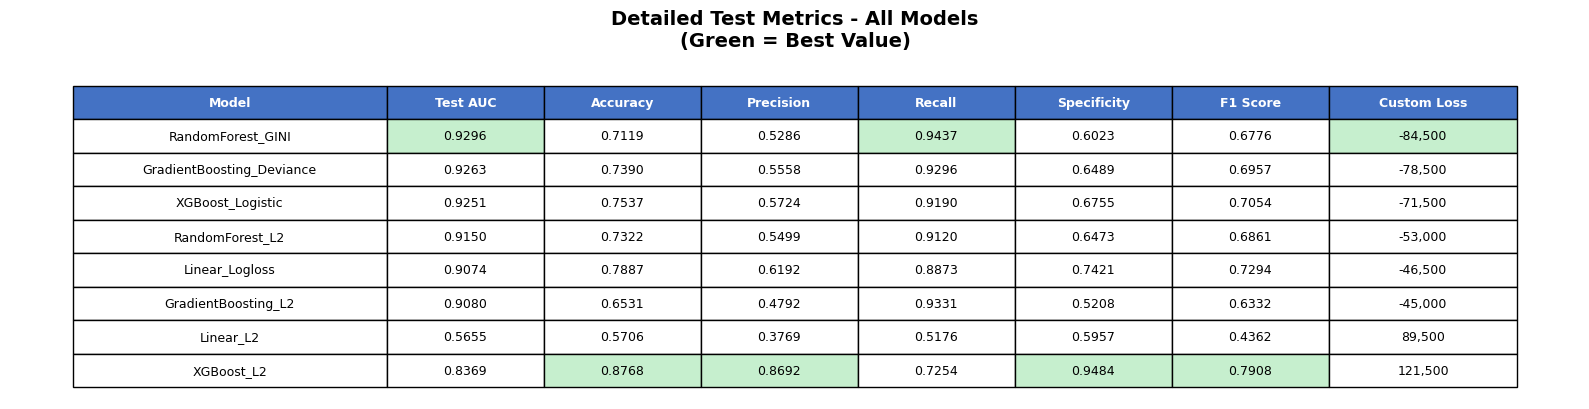


FINAL RECOMMENDATION
Best Overall Model: RandomForest_GINI
Category: RandomForest
CV Custom Loss: -81,250
Test Custom Loss: -84,500
Test AUC: 0.9296
Overfitting Gap: 0.0568
Max Depth Setting: 15
Average Actual Depth: 15.0

This model provides the best balance of:
  - Lowest custom loss (minimizing cost of misclassification)
  - Good generalization (controlled overfitting)
  - Strong predictive performance (high AUC)

✓ Analysis Complete!


In [ ]:
## STEP 5: Comprehensive Final Summary

print(f"\n{'='*80}")
print("STEP 5: FINAL MODEL COMPARISON AND SUMMARY")
print('='*80)

all_results = {**results_glassbox, **results_blackbox}

# Calculate test metrics for all models
all_metrics = []

for name, results in all_results.items():
    if 'y_test_proba' in results:
        scores = results['y_test_proba']
    else:
        scores = results['y_test_scores']
    
    y_pred = (scores >= results['threshold']).astype(int)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    # Model category
    if name in results_glassbox:
        category = 'Glassbox'
        train_auc = results.get('train_auc', results['cv_auc'])
        overfit_gap = train_auc - results['cv_auc']
    elif 'RandomForest' in name:
        category = 'RandomForest'
        overfit_gap = results['test_overfit_gap']
    elif 'XGBoost' in name:
        category = 'XGBoost'
        overfit_gap = results['test_overfit_gap']
    else:
        category = 'GradientBoosting'
        overfit_gap = results['test_overfit_gap']
    
    # Get max_depth if available
    max_depth = results.get('params', {}).get('max_depth', 'N/A')
    avg_depth = 'N/A'
    if results.get('tree_depths'):
        avg_depth = f"{np.mean(results['tree_depths']):.1f}"
    
    all_metrics.append({
        'Model': name,
        'Category': category,
        'Max_Depth': max_depth,
        'Avg_Depth': avg_depth,
        'CV_AUC': results['cv_auc'],
        'Test_AUC': results['test_auc'],
        'Overfit_Gap': overfit_gap,
        'Threshold': results['threshold'],
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1_Score': f1,
        'CV_CustomLoss': results['cv_loss'],
        'Test_CustomLoss': results['test_loss']
    })

# Create comprehensive comparison dataframe
comparison_df = pd.DataFrame(all_metrics).sort_values('CV_CustomLoss')

print("\n" + "="*140)
print("COMPLETE MODEL PERFORMANCE COMPARISON (Sorted by CV Custom Loss)")
print("="*140)
print(comparison_df.to_string(index=False))

# Create visual comparison table with overfitting info
fig, ax = plt.subplots(figsize=(18, len(all_metrics) * 0.4 + 1))
ax.axis('tight')
ax.axis('off')

# Prepare data for table
table_data = comparison_df[['Model', 'Category', 'Max_Depth', 'Avg_Depth', 
                            'Test_AUC', 'Overfit_Gap', 'Recall', 
                            'Test_CustomLoss', 'Threshold']].values
table_cols = ['Model', 'Category', 'Max Depth', 'Avg Depth',
              'Test AUC', 'Overfit Gap', 'Recall', 'Custom Loss', 'Threshold']

# Format numeric values
formatted_data = []
for row in table_data:
    formatted_row = [
        row[0],  # Model
        row[1],  # Category
        str(row[2]),  # Max Depth
        str(row[3]),  # Avg Depth
        f"{row[4]:.4f}",  # Test AUC
        f"{row[5]:.4f}",  # Overfit Gap
        f"{row[6]:.4f}",  # Recall
        f"{row[7]:,.0f}",  # Custom Loss
        f"{row[8]:.3f}"   # Threshold
    ]
    formatted_data.append(formatted_row)

table = ax.table(cellText=formatted_data, colLabels=table_cols, 
                cellLoc='center', loc='center',
                colWidths=[0.18, 0.11, 0.08, 0.08, 0.08, 0.09, 0.08, 0.12, 0.08])

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 2)

# Color header
for i in range(len(table_cols)):
    table[(0, i)].set_facecolor('#4472C4')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Color cells based on values
for row_idx in range(len(formatted_data)):
    # Color overfit gap (red if > 0.05, yellow if > 0.03, green otherwise)
    overfit_val = float(formatted_data[row_idx][5])
    if overfit_val > 0.05:
        table[(row_idx + 1, 5)].set_facecolor('#FFC7CE')  # Red
    elif overfit_val > 0.03:
        table[(row_idx + 1, 5)].set_facecolor('#FFEB9C')  # Yellow
    else:
        table[(row_idx + 1, 5)].set_facecolor('#C6EFCE')  # Green

# Color best AUC (green)
auc_values = [float(formatted_data[i][4]) for i in range(len(formatted_data))]
best_auc_idx = auc_values.index(max(auc_values))
table[(best_auc_idx + 1, 4)].set_facecolor('#C6EFCE')

# Color best custom loss (green)
losses = [float(formatted_data[i][7].replace(',', '')) for i in range(len(formatted_data))]
best_loss_idx = losses.index(min(losses))
table[(best_loss_idx + 1, 7)].set_facecolor('#C6EFCE')

plt.title('Complete Model Performance Comparison\n(Green=Best, Red=High Overfitting)', 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Best models by category
print(f"\n{'='*80}")
print("BEST MODEL FROM EACH CATEGORY")
print('='*80)

best_by_category = comparison_df.groupby('Category').first().reset_index()
print(best_by_category[['Category', 'Model', 'CV_CustomLoss', 'Test_CustomLoss', 'Test_AUC']].to_string(index=False))

# Plot ROC curves for best models from each category
plt.figure(figsize=(10, 8))
colors = ['blue', 'orange', 'green', 'red']
best_models_list = []

for (cat, row), color in zip(best_by_category.iterrows(), colors):
    model_name = row['Model']
    results = all_results[model_name]
    
    if 'y_test_proba' in results:
        scores = results['y_test_proba']
    else:
        scores = results['y_test_scores']
    
    fpr, tpr, _ = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, linewidth=2.5, color=color,
             label=f"{row['Category']}: {model_name}\n(AUC = {row['Test_AUC']:.3f})")
    
    best_models_list.append(model_name)

plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Chance (AUC = 0.5)')
plt.xlabel('False positive rate', fontsize=13)
plt.ylabel('True positive rate', fontsize=13)
plt.title('Best Models from Each Category - ROC Curves (Test Set)', 
          fontsize=15, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Detailed metrics for best models from each category
print(f"\n{'='*80}")
print("DETAILED TEST METRICS - BEST MODELS FROM EACH CATEGORY")
print('='*80)

for model_name in best_models_list:
    results = all_results[model_name]
    
    if 'y_test_proba' in results:
        scores = results['y_test_proba']
    else:
        scores = results['y_test_scores']
    
    y_pred = (scores >= results['threshold']).astype(int)
    
    print(f"\n{'='*80}")
    print(f"{model_name}")
    print('='*80)
    print(f"Threshold: {results['threshold']:.3f}")
    print(f"Test AUC: {results['test_auc']:.4f}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
    print(f"Recall (Sensitivity): {recall_score(y_test, y_pred):.4f}")
    print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
    print(f"Custom Loss: {results['test_loss']:,.0f}")
    
    cm = results['cm_test']
    print(f"\nTest Confusion Matrix:")
    print(f"              Predicted")
    print(f"               0      1")
    print(f"Actual 0  {cm[0,0]:5d}  {cm[0,1]:5d}")
    print(f"Actual 1  {cm[1,0]:5d}  {cm[1,1]:5d}")
    
    # Calculate specificity and other metrics
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp)
    sensitivity = tp / (tp + fn)
    
    print(f"\nSensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")

# Plot all models ROC curves on one figure
print(f"\n{'='*80}")
print("ALL MODELS ROC COMPARISON")
print('='*80)

plt.figure(figsize=(12, 9))

# Define color map for categories
category_colors = {
    'Glassbox': ['#1f77b4', '#aec7e8'],
    'RandomForest': ['#ff7f0e', '#ffbb78'],
    'XGBoost': ['#2ca02c', '#98df8a'],
    'GradientBoosting': ['#d62728', '#ff9896']
}

legend_handles = []
for name, results in all_results.items():
    if 'y_test_proba' in results:
        scores = results['y_test_proba']
    else:
        scores = results['y_test_scores']
    
    fpr, tpr, _ = roc_curve(y_test, scores)
    
    # Determine category and color
    if name in results_glassbox:
        category = 'Glassbox'
        color_idx = list(results_glassbox.keys()).index(name)
    elif 'RandomForest' in name:
        category = 'RandomForest'
        color_idx = 0 if 'L2' in name else 1
    elif 'XGBoost' in name:
        category = 'XGBoost'
        color_idx = 0 if 'L2' in name else 1
    else:
        category = 'GradientBoosting'
        color_idx = 0 if 'L2' in name else 1
    
    color = category_colors[category][color_idx]
    line = plt.plot(fpr, tpr, linewidth=2, color=color,
                    label=f"{name} (AUC = {results['test_auc']:.3f})")
    
    if color_idx == 0:
        legend_handles.append(line[0])

plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Chance (AUC = 0.5)')
plt.xlabel('False positive rate', fontsize=13)
plt.ylabel('True positive rate', fontsize=13)
plt.title('All Models - ROC Curves Comparison (Test Set)', 
          fontsize=15, fontweight='bold')
plt.legend(loc='lower right', fontsize=9, ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Create comprehensive metrics table for all models
print(f"\n{'='*80}")
print("COMPREHENSIVE TEST METRICS - ALL MODELS")
print('='*80)

detailed_metrics = []

for name, results in all_results.items():
    if 'y_test_proba' in results:
        scores = results['y_test_proba']
    else:
        scores = results['y_test_scores']
    
    y_pred = (scores >= results['threshold']).astype(int)
    cm = results['cm_test']
    tn, fp, fn, tp = cm.ravel()
    
    detailed_metrics.append({
        'Model': name,
        'Threshold': results['threshold'],
        'Test_AUC': results['test_auc'],
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred),
        'Specificity': tn / (tn + fp),
        'F1_Score': f1_score(y_test, y_pred),
        'Test_CustomLoss': results['test_loss']
    })

detailed_df = pd.DataFrame(detailed_metrics).sort_values('Test_CustomLoss')

print("\n")
print(detailed_df.to_string(index=False))

# Create visual detailed metrics table
fig, ax = plt.subplots(figsize=(16, len(detailed_metrics) * 0.4 + 1))
ax.axis('tight')
ax.axis('off')

# Format data for table
table_data = detailed_df[['Model', 'Test_AUC', 'Accuracy', 'Precision', 
                          'Recall', 'Specificity', 'F1_Score', 'Test_CustomLoss']].values

table_cols = ['Model', 'Test AUC', 'Accuracy', 'Precision', 
              'Recall', 'Specificity', 'F1 Score', 'Custom Loss']

formatted_table_data = []
for row in table_data:
    formatted_row = [
        row[0],  # Model
        f"{row[1]:.4f}",  # Test AUC
        f"{row[2]:.4f}",  # Accuracy
        f"{row[3]:.4f}",  # Precision
        f"{row[4]:.4f}",  # Recall
        f"{row[5]:.4f}",  # Specificity
        f"{row[6]:.4f}",  # F1 Score
        f"{row[7]:,.0f}"  # Custom Loss
    ]
    formatted_table_data.append(formatted_row)

table = ax.table(cellText=formatted_table_data, colLabels=table_cols,
                cellLoc='center', loc='center',
                colWidths=[0.20, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.12])

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2)

# Color header
for i in range(len(table_cols)):
    table[(0, i)].set_facecolor('#4472C4')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Highlight best values
for col_idx in range(1, 7):  # AUC through F1 Score
    values = [float(formatted_table_data[i][col_idx]) for i in range(len(formatted_table_data))]
    best_idx = values.index(max(values))
    table[(best_idx + 1, col_idx)].set_facecolor('#C6EFCE')

# Highlight best custom loss (lowest)
loss_values = [float(formatted_table_data[i][7].replace(',', '')) for i in range(len(formatted_table_data))]
best_loss_idx = loss_values.index(min(loss_values))
table[(best_loss_idx + 1, 7)].set_facecolor('#C6EFCE')

plt.title('Detailed Test Metrics - All Models\n(Green = Best Value)', 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Final recommendation
best_overall = comparison_df.iloc[0]
print(f"\n{'='*80}")
print("FINAL RECOMMENDATION")
print('='*80)
print(f"Best Overall Model: {best_overall['Model']}")
print(f"Category: {best_overall['Category']}")
print(f"CV Custom Loss: {best_overall['CV_CustomLoss']:,.0f}")
print(f"Test Custom Loss: {best_overall['Test_CustomLoss']:,.0f}")
print(f"Test AUC: {best_overall['Test_AUC']:.4f}")
print(f"Overfitting Gap: {best_overall['Overfit_Gap']:.4f}")

if best_overall['Max_Depth'] != 'N/A':
    print(f"Max Depth Setting: {best_overall['Max_Depth']}")
if best_overall['Avg_Depth'] != 'N/A':
    print(f"Average Actual Depth: {best_overall['Avg_Depth']}")

print(f"\nThis model provides the best balance of:")
print(f"  - Lowest custom loss (minimizing cost of misclassification)")
print(f"  - Good generalization (controlled overfitting)")
print(f"  - Strong predictive performance (high AUC)")
print('='*80)

print("\n✓ Analysis Complete!")